In [20]:
# ============================================================
# CONTEXTUAL HALLUCINATION DETECTOR (CHD)
# FULL FIXED EXPERIMENTAL PIPELINE (OPTIMIZED)
# ============================================================

import os
import re
import json
import hashlib
import random
import warnings
import joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
DATA_PATH = "apple_privacy_hallucination_10000.csv"
OUTPUT_DIR = Path("contextual_hallucination_detector_final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("CONTEXTUAL HALLUCINATION DETECTOR")
print("=" * 70)
print("\nData:", DATA_PATH)
print("Output:", OUTPUT_DIR)

# ============================================================
# 1. IMPORT ML/NLP LIBRARIES
# ============================================================
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score
)
from sklearn.calibration import CalibratedClassifierCV
from scipy.stats import spearmanr

from sentence_transformers import SentenceTransformer
from transformers import pipeline
from xgboost import XGBClassifier

# ============================================================
# 2. LOAD DATASET
# ============================================================
df = pd.read_csv(DATA_PATH)
print("\nDataset shape:", df.shape)

required_columns = ["document", "topic", "question", "context", "claim", "label"]
missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# ============================================================
# 3. CLEAN DATA
# ============================================================
for col in required_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()

df = df[
    (df["context"].str.len() > 0) &
    (df["claim"].str.len() > 0) &
    (df["label"].str.len() > 0)
].copy()

print("\nAfter cleaning:", df.shape)
print("\nLabel distribution:\n", df["label"].value_counts())

# ============================================================
# 4. NORMALIZATION
# ============================================================
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s.%$€£-]", " ", text)
    return text.strip()

df["context_normalized"] = df["context"].apply(normalize_text)
df["claim_normalized"] = df["claim"].apply(normalize_text)

# ============================================================
# 5. STRONGER SOURCE-FACT GROUPING
# ============================================================
def normalize_group_component(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", "", text)
    return text.strip()

def make_source_fact_id(row):
    source_lines = str(row.get("source_lines", "")).strip()
    evidence = str(row.get("evidence", "")).strip()
    context = str(row["context"]).strip()

    if source_lines and source_lines.lower() not in ["nan", "none", ""]:
        base = f"{row['document']}||{row['topic']}||{source_lines}"
    elif evidence and evidence.lower() not in ["nan", "none", ""]:
        base = f"{row['document']}||{row['topic']}||{normalize_group_component(evidence)}"
    else:
        base = f"{row['document']}||{row['topic']}||{normalize_group_component(context)}"

    return hashlib.md5(base.encode("utf-8")).hexdigest()

df["source_fact_id"] = df.apply(make_source_fact_id, axis=1)
print(f"\nUnique source-fact groups: {df['source_fact_id'].nunique()}")

# ============================================================
# 6 & 7. LABEL ENCODING
# ============================================================
label_encoder = LabelEncoder()
df["label_id"] = label_encoder.fit_transform(df["label"])
labels = list(label_encoder.classes_)

# ============================================================
# 8 & 9. GROUP-SAFE SPLIT & VERIFY
# ============================================================
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_val_idx, test_idx = next(gss1.split(df, groups=df["source_fact_id"]))
train_val = df.iloc[train_val_idx].copy()
test_df = df.iloc[test_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, val_idx = next(gss2.split(train_val, groups=train_val["source_fact_id"]))
train_df = train_val.iloc[train_idx].copy()
val_df = train_val.iloc[val_idx].copy()

print(f"\nSplit sizes: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

train_groups = set(train_df["source_fact_id"])
val_groups = set(val_df["source_fact_id"])
test_groups = set(test_df["source_fact_id"])

assert len(train_groups & val_groups) == 0
assert len(train_groups & test_groups) == 0
assert len(val_groups & test_groups) == 0
print("✓ No source-fact leakage detected.")

# ============================================================
# 10. SAVE SPLITS
# ============================================================
train_df.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "validation_split.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_split.csv", index=False)

# ============================================================
# 11 & 12. LOAD MODELS
# ============================================================
print("\nLoading SentenceTransformer...")
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Loading NLI model...")
nli_model_name = "cross-encoder/nli-deberta-v3-base"
# FIX: Added truncation and max_length to prevent tensor warnings
nli_model = pipeline(
    task="text-classification",
    model=nli_model_name,
    tokenizer=nli_model_name,
    top_k=None,
    truncation=True,
    max_length=512
)
print("✓ Models loaded")

# ============================================================
# 13, 14, 15. TEXT UTILITIES & NLI
# ============================================================
STOPWORDS = {"the", "a", "an", "and", "or", "of", "to", "in", "on", "for", "with", "by", "is", "are", "was", "were", "be", "as", "this", "that", "these", "those", "it", "its", "from", "at", "which", "their", "they", "you", "your", "we", "our"}

def tokenize(text):
    return [t for t in re.findall(r"\b\w+\b", str(text).lower()) if t not in STOPWORDS]

def lexical_overlap(context, claim):
    c, q = set(tokenize(context)), set(tokenize(claim))
    return len(c & q) / len(q) if q else 0.0

def context_coverage(context, claim):
    c_tokens, q_tokens = set(tokenize(context)), tokenize(claim)
    return sum(t in c_tokens for t in q_tokens) / len(q_tokens) if q_tokens else 0.0

def extract_entities(text):
    return {normalize_text(x) for x in re.findall(r"\b[A-Z][a-zA-Z0-9]*(?:\s+[A-Z][a-zA-Z0-9]*)*\b", str(text)) if len(x.strip()) > 1}

def entity_consistency(context, claim):
    c_ent, q_ent = extract_entities(context), extract_entities(claim)
    return len(q_ent & c_ent) / len(q_ent) if q_ent else 1.0

def extract_numbers(text):
    return {n.replace(",", "") for n in re.findall(r"\b\d+(?:[.,]\d+)?%?\b", str(text))}

def number_consistency(context, claim):
    c_num, q_num = extract_numbers(context), extract_numbers(claim)
    return len(q_num & c_num) / len(q_num) if q_num else 1.0

NEGATION_WORDS = {"not", "never", "no", "without", "cannot", "can't", "doesn't", "doesnt", "isn't", "isnt", "aren't", "arent", "won't", "wont", "neither", "nor"}

def lexical_contradiction(context, claim):
    c_neg = len(set(tokenize(context)) & NEGATION_WORDS) > 0
    q_neg = len(set(tokenize(claim)) & NEGATION_WORDS) > 0
    return 1.0 if c_neg != q_neg else 0.0

def _resolve_nli_label_indices():
    """Resolve entailment / contradiction / neutral indices from model config.

    This deliberately fails loudly if the model does not expose recognizable
    NLI labels, rather than silently returning zero-valued features.
    """
    id2label = {
        int(k): str(v).lower()
        for k, v in nli_model.model.config.id2label.items()
    }

    resolved = {}
    for idx, label in id2label.items():
        if "entail" in label:
            resolved["entailment"] = idx
        elif "contrad" in label:
            resolved["contradiction"] = idx
        elif "neutral" in label:
            resolved["neutral"] = idx

    missing = [k for k in ("entailment", "contradiction", "neutral") if k not in resolved]
    if missing:
        raise ValueError(
            "Could not resolve NLI labels from model config. "
            f"id2label={id2label}; missing={missing}. "
            "Use an NLI model whose config exposes entailment, contradiction, and neutral labels."
        )

    return resolved


NLI_LABEL_INDEX = _resolve_nli_label_indices()
print("NLI label mapping:", NLI_LABEL_INDEX)


def nli_scores_batch(contexts, claims, batch_size=32):
    """Compute proper sentence-pair NLI probabilities in batches."""
    contexts = [str(x) for x in contexts]
    claims = [str(x) for x in claims]

    if len(contexts) != len(claims):
        raise ValueError("contexts and claims must have the same length")

    if len(contexts) == 0:
        return np.empty((0, 3), dtype=np.float32)

    model = nli_model.model
    tokenizer = nli_model.tokenizer
    model.eval()
    device = next(model.parameters()).device

    all_scores = []

    for start in range(0, len(contexts), batch_size):
        end = min(start + batch_size, len(contexts))

        encoded = tokenizer(
            contexts[start:end],
            claims[start:end],
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt",
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}

        with torch.inference_mode():
            logits = model(**encoded).logits
            probs = F.softmax(logits, dim=-1).detach().cpu().numpy()

        batch_scores = np.column_stack([
            probs[:, NLI_LABEL_INDEX["entailment"]],
            probs[:, NLI_LABEL_INDEX["contradiction"]],
            probs[:, NLI_LABEL_INDEX["neutral"]],
        ])
        all_scores.append(batch_scores.astype(np.float32))

    scores = np.vstack(all_scores)

    if not np.isfinite(scores).all():
        raise ValueError("Non-finite values detected in NLI probabilities.")

    sums = scores.sum(axis=1)
    if not np.allclose(sums, 1.0, atol=1e-4):
        raise ValueError(
            "NLI probabilities do not sum to 1. "
            f"Observed range: {sums.min():.6f}..{sums.max():.6f}"
        )

    return scores


def nli_scores(context, claim):
    """Single-example wrapper retained for compatibility."""
    scores = nli_scores_batch([context], [claim], batch_size=1)[0]
    return {
        "entailment": float(scores[0]),
        "contradiction": float(scores[1]),
        "neutral": float(scores[2]),
    }

# ============================================================
# 16 & 17. FEATURE EXTRACTION
# ============================================================
FEATURE_NAMES = [
    "semantic_similarity", "lexical_overlap", "context_coverage",
    "entity_consistency", "number_consistency", "entailment",
    "contradiction", "neutral", "lexical_contradiction",
    "claim_length", "context_length", "claim_context_ratio"
]

def compute_features(contexts, claims, batch_size=64, nli_batch_size=32):
    contexts, claims = list(contexts), list(claims)
    if len(contexts) != len(claims):
        raise ValueError("contexts and claims must have the same length")

    print(f"\nEncoding {len(contexts)} examples...")

    c_emb = sentence_model.encode(
        contexts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    q_emb = sentence_model.encode(
        claims,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    sem_sim = np.sum(c_emb * q_emb, axis=1)

    print("Computing batched NLI probabilities...")
    nli_matrix = nli_scores_batch(contexts, claims, batch_size=nli_batch_size)

    features = []
    for i, (context, claim) in enumerate(zip(contexts, claims)):
        c_tok, q_tok = tokenize(context), tokenize(claim)
        c_len, q_len = len(c_tok), len(q_tok)

        features.append([
            float(sem_sim[i]),
            lexical_overlap(context, claim),
            context_coverage(context, claim),
            entity_consistency(context, claim),
            number_consistency(context, claim),
            float(nli_matrix[i, 0]),
            float(nli_matrix[i, 1]),
            float(nli_matrix[i, 2]),
            lexical_contradiction(context, claim),
            float(q_len),
            float(c_len),
            float(q_len / c_len if c_len > 0 else 0.0),
        ])

    X = np.asarray(features, dtype=np.float32)

    if not np.isfinite(X).all():
        raise ValueError("Non-finite values detected in extracted features.")

    return X

X_train = compute_features(train_df["context"], train_df["claim"])
X_val = compute_features(val_df["context"], val_df["claim"])
X_test = compute_features(test_df["context"], test_df["claim"])

# ------------------------------------------------------------
# NLI FEATURE HEALTH CHECK — fail loudly if extraction collapses
# ------------------------------------------------------------
nli_feature_indices = [FEATURE_NAMES.index(x) for x in ["entailment", "contradiction", "neutral"]]
nli_train = X_train[:, nli_feature_indices]
nli_sums = nli_train.sum(axis=1)

print("\n" + "=" * 70)
print("NLI FEATURE HEALTH CHECK")
print("=" * 70)
for j, feature_name in enumerate(["entailment", "contradiction", "neutral"]):
    values = nli_train[:, j]
    print(
        f"{feature_name:15s} min={values.min():.6f} max={values.max():.6f} "
        f"mean={values.mean():.6f} std={values.std():.6f} unique={len(np.unique(values))}"
    )
print(f"NLI probability-sum range: {nli_sums.min():.6f} .. {nli_sums.max():.6f}")

if np.allclose(nli_train, 0.0):
    raise RuntimeError("NLI features collapsed to all zeros. Stop before model training.")
if not np.allclose(nli_sums, 1.0, atol=1e-4):
    raise RuntimeError("NLI feature rows do not sum to 1. Stop before model training.")

y_train = train_df["label_id"].values
y_val = val_df["label_id"].values
y_test = test_df["label_id"].values

# ============================================================
# 18. SAVE FEATURES
# ============================================================
pd.DataFrame(X_train, columns=FEATURE_NAMES).to_csv(OUTPUT_DIR / "train_features.csv", index=False)
pd.DataFrame(X_val, columns=FEATURE_NAMES).to_csv(OUTPUT_DIR / "validation_features.csv", index=False)
pd.DataFrame(X_test, columns=FEATURE_NAMES).to_csv(OUTPUT_DIR / "test_features.csv", index=False)

# ============================================================
# 19 & 20. XGBOOST & EVALUATION
# ============================================================
def build_xgb():
    return XGBClassifier(
        n_estimators=400, max_depth=6, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85, objective="multi:softprob",
        num_class=len(labels), eval_metric="mlogloss", random_state=SEED, n_jobs=-1
    )

def evaluate_model(model, X, y, split_name):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)
    accuracy = accuracy_score(y, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(y, predictions, average="macro", zero_division=0)
    weighted_f1 = precision_recall_fscore_support(y, predictions, average="weighted", zero_division=0)[2]

    print(f"\n{'='*70}\n{split_name}\n{'='*70}")
    print(f"Accuracy       : {accuracy:.4f}")
    print(f"Macro F1       : {f1:.4f}")
    print(f"Weighted F1    : {weighted_f1:.4f}")
    print("\nClassification report:\n", classification_report(y, predictions, target_names=labels, digits=4, zero_division=0))

    return {"accuracy": accuracy, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1, "weighted_f1": weighted_f1, "predictions": predictions, "probabilities": probabilities}

# ============================================================
# 21. TRAIN MAIN MODEL
# ============================================================
print("\nTraining full XGBoost model...")
main_model = build_xgb()
main_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("✓ Base training completed")

# ============================================================
# 21.5. CALIBRATE MODEL PROBABILITIES
# ============================================================
print("\nCalibrating model probabilities (Isotonic Regression)...")
calibrated_model = CalibratedClassifierCV(main_model, method="isotonic", cv="prefit")
calibrated_model.fit(X_val, y_val)
print("✓ Model calibrated.")

# ============================================================
# 22. MAIN EVALUATION (CALIBRATED)
# ============================================================
val_results = evaluate_model(calibrated_model, X_val, y_val, "VALIDATION RESULTS (CALIBRATED)")
test_results = evaluate_model(calibrated_model, X_test, y_test, "TEST RESULTS (CALIBRATED)")

# ============================================================
# 23, 24, 25. SAVE ARTIFACTS
# ============================================================
cm = confusion_matrix(y_test, test_results["predictions"])
pd.DataFrame(cm, index=labels, columns=labels).to_csv(OUTPUT_DIR / "test_confusion_matrix.csv")

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Contextual Hallucination Detector - Test Confusion Matrix")
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=300)
plt.close()

importance = main_model.feature_importances_
importance_df = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "importance": importance,
}).sort_values("importance", ascending=False).reset_index(drop=True)
importance_df.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

plt.figure(figsize=(9, 6))
plt.barh(importance_df["feature"], importance_df["importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=300)
plt.close()

main_model.save_model(OUTPUT_DIR / "chd_xgboost_model.json")
joblib.dump(calibrated_model, OUTPUT_DIR / "chd_calibrated_model.pkl")
print("\n✓ Base XGBoost and Calibrated models saved.")

# ============================================================
# 26 & 26.5. CONFIDENCE ANALYSIS & ABSTENTION
# ============================================================
test_probabilities = test_results["probabilities"]
test_predictions = test_results["predictions"]
confidence = np.max(test_probabilities, axis=1)
correct = (test_predictions == y_test)

print(f"\nMean confidence: {confidence.mean():.4f}")
print(f"Correct mean confidence: {confidence[correct].mean():.4f}")
if (~correct).sum() > 0:
    print(f"Incorrect mean confidence: {confidence[~correct].mean():.4f}")

print("\n" + "=" * 70)
print("CONFIDENCE THRESHOLDING (ABSTENTION)")
print("=" * 70)
print(f"{'Threshold':<12}{'Accuracy':<12}{'Coverage':<12}{'N Predicted':<12}")
print("-" * 48)

abstention_records = []
for t in np.arange(0.50, 1.00, 0.05):
    mask = confidence >= t
    n_predicted = int(mask.sum())
    if n_predicted > 0:
        acc = accuracy_score(y_test[mask], test_predictions[mask])
        cov = n_predicted / len(y_test)
    else:
        acc, cov = 0.0, 0.0
    abstention_records.append({"threshold": round(float(t), 2), "accuracy": float(acc), "coverage": float(cov), "n_predicted": n_predicted})
    print(f"{t:<12.2f}{acc:<12.4f}{cov:<12.4f}{n_predicted:<12}")

pd.DataFrame(abstention_records).to_csv(OUTPUT_DIR / "abstention_analysis.csv", index=False)

plt.figure(figsize=(9, 6))
plt.plot([r["threshold"] for r in abstention_records], [r["accuracy"] for r in abstention_records], marker="o", label="Accuracy")
plt.plot([r["threshold"] for r in abstention_records], [r["coverage"] for r in abstention_records], marker="s", label="Coverage")
plt.xlabel("Confidence Threshold")
plt.ylabel("Value")
plt.title("Accuracy vs Coverage at Different Confidence Thresholds")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "abstention_analysis.png", dpi=300)
plt.close()

# ============================================================
# 27. ERROR ANALYSIS
# ============================================================
error_df = test_df.copy()
error_df["true_label"] = label_encoder.inverse_transform(y_test)
error_df["predicted_label"] = label_encoder.inverse_transform(test_predictions)
error_df["confidence"] = confidence
errors = error_df[error_df["true_label"] != error_df["predicted_label"]].copy()

print(f"\nNumber of test errors: {len(errors)} ({len(errors)/len(test_df)*100:.2f}%)")
errors.to_csv(OUTPUT_DIR / "test_errors.csv", index=False)

# ============================================================
# 28 & 29. CONTEXTUAL HALLUCINATION SCORE (CHS)
# ============================================================
def calculate_chs(X):
    idx = {name: i for i, name in enumerate(FEATURE_NAMES)}
    grounding = 0.30*X[:, idx["entailment"]] + 0.20*X[:, idx["semantic_similarity"]] + 0.15*X[:, idx["context_coverage"]] + 0.10*X[:, idx["entity_consistency"]] + 0.10*X[:, idx["number_consistency"]]
    unsupported_signal = 0.30*X[:, idx["contradiction"]] + 0.20*X[:, idx["neutral"]] + 0.20*(1-X[:, idx["semantic_similarity"]]) + 0.10*(1-X[:, idx["context_coverage"]]) + 0.10*(1-X[:, idx["entity_consistency"]]) + 0.10*X[:, idx["lexical_contradiction"]]
    return np.clip(0.55 * unsupported_signal + 0.45 * (1 - grounding), 0.0, 1.0)

test_chs = calculate_chs(X_test)
chs_df = test_df.copy()
chs_df["CHS"] = test_chs
chs_df["predicted_label"] = label_encoder.inverse_transform(test_predictions)

chs_summary = chs_df.groupby("label")["CHS"].agg(["mean", "std", "min", "max"]).sort_values("mean", ascending=False)
print("\nCHS by true label:\n", chs_summary)
chs_summary.to_csv(OUTPUT_DIR / "chs_by_label.csv")

plt.figure(figsize=(9, 6))
for label in labels:
    plt.hist(chs_df.loc[chs_df["label"] == label, "CHS"], bins=30, alpha=0.5, label=label)
plt.xlabel("Contextual Hallucination Score")
plt.ylabel("Frequency")
plt.title("CHS Distribution by Class")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "chs_distribution.png", dpi=300)
plt.close()

# ============================================================
# 30. BINARY GROUNDING TASK
# ============================================================
binary_y_train = (train_df["label"] != "SUPPORTED").astype(int).values
binary_y_test = (test_df["label"] != "SUPPORTED").astype(int).values
binary_model = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, objective="binary:logistic", random_state=SEED, n_jobs=-1)
binary_model.fit(X_train, binary_y_train, verbose=False)
binary_prob = binary_model.predict_proba(X_test)[:, 1]
binary_pred = (binary_prob >= 0.5).astype(int)

binary_accuracy = accuracy_score(binary_y_test, binary_pred)
binary_f1 = precision_recall_fscore_support(binary_y_test, binary_pred, average="binary", zero_division=0)[2]
binary_auc = roc_auc_score(binary_y_test, binary_prob)
print(f"\nBinary Grounding -> Acc: {binary_accuracy:.4f}, F1: {binary_f1:.4f}, AUROC: {binary_auc:.4f}")

# ============================================================
# 31 & 32. ABLATION STUDY
# ============================================================
print("\n" + "=" * 70)
print("ABLATION STUDY")
print("=" * 70)

feature_groups = {
    "Lexical Only": ["lexical_overlap", "context_coverage", "lexical_contradiction"],
    "Semantic Only": ["semantic_similarity"],
    "NLI Only": ["entailment", "contradiction", "neutral"],
    "Semantic + NLI": ["semantic_similarity", "entailment", "contradiction", "neutral"],
    "Semantic + NLI + Consistency": ["semantic_similarity", "entailment", "contradiction", "neutral", "entity_consistency", "number_consistency", "context_coverage", "lexical_contradiction"],
    "Full Model": FEATURE_NAMES
}

ablation_results = []
for name, selected_features in feature_groups.items():
    indices = [FEATURE_NAMES.index(f) for f in selected_features]
    model = build_xgb()
    model.fit(X_train[:, indices], y_train, verbose=False)
    predictions = model.predict(X_test[:, indices])
    acc = accuracy_score(y_test, predictions)
    f1 = precision_recall_fscore_support(y_test, predictions, average="macro", zero_division=0)[2]
    ablation_results.append({"model": name, "accuracy": acc, "macro_f1": f1})
    print(f"{name:35s} Accuracy={acc:.4f} Macro-F1={f1:.4f}")

pd.DataFrame(ablation_results).to_csv(OUTPUT_DIR / "ablation_results.csv", index=False)

plt.figure(figsize=(10, 6))
plt.bar([r["model"] for r in ablation_results], [r["macro_f1"] for r in ablation_results])
plt.ylabel("Macro-F1")
plt.xlabel("Feature Configuration")
plt.title("Ablation Study")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ablation_macro_f1.png", dpi=300)
plt.close()

# ============================================================
# 33, 34, 35. PROGRESSIVE CONTEXT DEGRADATION (OPTIMIZED BATCHING)
# ============================================================
def split_sentences(text):
    sentences = re.split(r"(?<=[.!?])\s+", str(text))
    return [s.strip() for s in sentences if s.strip()]

def rank_sentences_by_claim_relevance(context, claim):
    sentences = split_sentences(context)
    if len(sentences) <= 1:
        return sentences
    claim_embedding = sentence_model.encode([claim], convert_to_numpy=True, normalize_embeddings=True)[0]
    sentence_embeddings = sentence_model.encode(sentences, convert_to_numpy=True, normalize_embeddings=True)
    similarities = sentence_embeddings @ claim_embedding
    return [sentence for _, sentence in sorted(zip(similarities, sentences), key=lambda x: x[0], reverse=True)]

def degrade_by_evidence_percentage(context, claim, percentage):
    sentences = rank_sentences_by_claim_relevance(context, claim)
    if len(sentences) <= 1:
        return context
    remove_n = min(int(round(len(sentences) * percentage)), len(sentences) - 1)
    return " ".join(sentences[remove_n:])

DEGRADATION_SAMPLE_SIZE = min(300, len(test_df))
degradation_sample = test_df.sample(DEGRADATION_SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)
degradation_levels = [0.00, 0.10, 0.30, 0.50, 0.70]

print("\nRunning progressive context degradation...")

# OPTIMIZATION: Collect all data first, then batch process ONCE
all_degraded_contexts = []
all_degraded_claims = []
row_metadata = []

for idx, row in degradation_sample.iterrows():
    original_context = row["context"]
    claim = row["claim"]
    
    for level in degradation_levels:
        degraded_context = degrade_by_evidence_percentage(original_context, claim, level)
        all_degraded_contexts.append(degraded_context)
        all_degraded_claims.append(claim)
        row_metadata.append({
            "id": row.get("id", idx),
            "label": row["label"],
            "claim": claim,
            "degradation_level": level,
            "degradation_percent": int(level * 100),
            "context_length_original": len(tokenize(original_context)),
            "context_length_degraded": len(tokenize(degraded_context))
        })
        
    if (idx + 1) % 50 == 0:
        print(f"Prepared {idx + 1}/{DEGRADATION_SAMPLE_SIZE} samples...")

# Single batched feature computation (eliminates 1500x progress bar spam)
print(f"\nComputing features for all {len(all_degraded_contexts)} degraded examples in a single batch...")
X_all_deg = compute_features(all_degraded_contexts, all_degraded_claims, batch_size=64)

print("Calculating CHS for all degraded examples...")
all_chs = calculate_chs(X_all_deg)

for i, meta in enumerate(row_metadata):
    meta["CHS"] = float(all_chs[i])

degradation_df = pd.DataFrame(row_metadata)
degradation_df.to_csv(OUTPUT_DIR / "multilevel_context_degradation.csv", index=False)

degradation_summary = degradation_df.groupby("degradation_percent")["CHS"].agg(["mean", "std", "min", "max"]).reset_index()
print("\nProgressive degradation summary:\n", degradation_summary)
degradation_summary.to_csv(OUTPUT_DIR / "multilevel_context_degradation_summary.csv", index=False)

plt.figure(figsize=(9, 6))
plt.errorbar(degradation_summary["degradation_percent"], degradation_summary["mean"], yerr=degradation_summary["std"], marker="o")
plt.xlabel("Claim-Relevant Evidence Removed (%)")
plt.ylabel("Mean CHS")
plt.title("Effect of Progressive Context Degradation on CHS")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "progressive_context_degradation.png", dpi=300)
plt.close()

# ============================================================
# 37. SPEARMAN CORRELATION
# ============================================================
rho, p_value = spearmanr(degradation_df["degradation_percent"], degradation_df["CHS"])
print("\n" + "=" * 70)
print("DEGRADATION MONOTONICITY")
print("=" * 70)
print(f"Spearman rho = {rho:.4f}")
print(f"p-value      = {p_value:.6e}")

# ============================================================
# 40 & 41. CALIBRATION ANALYSIS & ECE
# ============================================================
calibration_bins = pd.DataFrame({"confidence": confidence, "correct": correct.astype(int)})
calibration_bins["bin"] = pd.cut(calibration_bins["confidence"], bins=[0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0], include_lowest=True)
calibration_summary = calibration_bins.groupby("bin", observed=True).agg(count=("correct", "size"), mean_confidence=("confidence", "mean"), accuracy=("correct", "mean")).reset_index()

print("\nConfidence calibration (post isotonic):\n", calibration_summary)
calibration_summary.to_csv(OUTPUT_DIR / "confidence_calibration.csv", index=False)

ece = sum((row["count"]/len(calibration_bins)) * abs(row["accuracy"] - row["mean_confidence"]) for _, row in calibration_summary.iterrows() if row["count"] > 0)
print(f"\nApproximate ECE (post-calibration): {ece:.6f}")

plt.figure(figsize=(9, 6))
plt.plot(calibration_summary["mean_confidence"], calibration_summary["accuracy"], marker="o", label="Calibrated Model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")
plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Observed Accuracy")
plt.title("Confidence Calibration (Post Isotonic Regression)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confidence_calibration.png", dpi=300)
plt.close()

# ============================================================
# 44 & 46. FINAL SUMMARY & REPORT
# ============================================================
main_summary = {
    "dataset_size": int(len(df)),
    "train_size": int(len(train_df)),
    "validation_size": int(len(val_df)),
    "test_size": int(len(test_df)),
    "num_classes": len(labels),
    "classes": labels,
    "test_accuracy": float(test_results["accuracy"]),
    "test_macro_f1": float(test_results["macro_f1"]),
    "binary_grounding_auroc": float(binary_auc),
    "mean_test_confidence": float(confidence.mean()),
    "incorrect_test_examples": int((~correct).sum()),
    "approximate_ECE_post_calibration": float(ece),
    "degradation_spearman_rho": float(rho),
    "degradation_p_value": float(p_value)
}

with open(OUTPUT_DIR / "experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(main_summary, f, indent=4)

print("\n")
print("=" * 70)
print("FINAL EXPERIMENT REPORT")
print("=" * 70)
print(f"\nDataset: {len(df):,} examples | Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print(f"\nMain 4-way detector (calibrated): Accuracy = {test_results['accuracy']:.4f}, Macro F1 = {test_results['macro_f1']:.4f}")
print(f"Binary grounding: AUROC = {binary_auc:.4f}, F1 = {binary_f1:.4f}")
print(f"Test errors: {len(errors)} ({len(errors)/len(test_df)*100:.2f}%)")
print(f"Approximate ECE (post-calibration): {ece:.6f}")
print(f"Spearman rho (degradation): {rho:.4f} (p={p_value:.6e})")
print("\nAll outputs and plots saved to:")
print(OUTPUT_DIR)
print("\n" + "=" * 70)
print("PIPELINE COMPLETED SUCCESSFULLY")
print("=" * 70)

CONTEXTUAL HALLUCINATION DETECTOR

Data: apple_privacy_hallucination_10000.csv
Output: contextual_hallucination_detector_final

Dataset shape: (10000, 13)

After cleaning: (10000, 13)

Label distribution:
 label
UNSUPPORTED     2500
HALLUCINATED    2500
CONTRADICTED    2500
SUPPORTED       2500
Name: count, dtype: int64

Unique source-fact groups: 126

Split sizes: Train=5928, Val=1936, Test=2136
✓ No source-fact leakage detected.

Loading SentenceTransformer...
Loading NLI model...


Device set to use cuda:0


✓ Models loaded
NLI label mapping: {'contradiction': 0, 'entailment': 1, 'neutral': 2}

Encoding 5928 examples...


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 93/93 [00:01<00:00, 58.34it/s]


Computing batched NLI probabilities...

Encoding 1936 examples...


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 31/31 [00:00<00:00, 61.10it/s]


Computing batched NLI probabilities...

Encoding 2136 examples...


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 34/34 [00:00<00:00, 53.40it/s]


Computing batched NLI probabilities...

NLI FEATURE HEALTH CHECK
entailment      min=0.000002 max=0.998680 mean=0.205080 std=0.395490 unique=5918
contradiction   min=0.000011 max=0.999972 mean=0.550955 std=0.486482 unique=5255
neutral         min=0.000023 max=0.999783 mean=0.243965 std=0.409096 unique=5914
NLI probability-sum range: 1.000000 .. 1.000000

Training full XGBoost model...
✓ Base training completed

Calibrating model probabilities (Isotonic Regression)...
✓ Model calibrated.

VALIDATION RESULTS (CALIBRATED)
Accuracy       : 0.9917
Macro F1       : 0.9918
Weighted F1    : 0.9917

Classification report:
               precision    recall  f1-score   support

CONTRADICTED     0.9940    0.9960    0.9950       502
HALLUCINATED     0.9959    0.9837    0.9898       492
   SUPPORTED     1.0000    0.9956    0.9978       452
 UNSUPPORTED     0.9779    0.9918    0.9848       490

    accuracy                         0.9917      1936
   macro avg     0.9919    0.9918    0.9918      193

Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 37.20it/s]


Computing batched NLI probabilities...
Calculating CHS for all degraded examples...

Progressive degradation summary:
    degradation_percent      mean       std       min       max
0                    0  0.469888  0.159778  0.091918  0.680659
1                   10  0.469888  0.159778  0.091918  0.680659
2                   30  0.482458  0.158103  0.105054  0.731847
3                   50  0.482458  0.158103  0.105054  0.731847
4                   70  0.482458  0.158103  0.105054  0.731847

DEGRADATION MONOTONICITY
Spearman rho = 0.0454
p-value      = 7.863401e-02

Confidence calibration (post isotonic):
             bin  count  mean_confidence  accuracy
0    (0.5, 0.6]      5         0.553891  0.600000
1    (0.6, 0.7]     16         0.657641  0.562500
2    (0.7, 0.8]     12         0.750653  0.666667
3    (0.8, 0.9]      5         0.868220  1.000000
4   (0.9, 0.95]     19         0.940941  1.000000
5  (0.95, 0.99]    475         0.981791  0.991579
6   (0.99, 1.0]   1604         0.99

In [21]:
# ============================================================
# CHD PIPELINE — CONFERENCE-READY EXTENSIONS
# Paste this AFTER the "FINAL SUMMARY & REPORT" section of the
# original script. It reuses every variable already defined
# there (df, train_df, test_df, X_train, X_test, y_test,
# main_model, calibrated_model, binary_model, sentence_model,
# nli_model, label_encoder, labels, FEATURE_NAMES,
# compute_features, calculate_chs, OUTPUT_DIR, confidence,
# correct, test_predictions, test_probabilities, errors,
# main_summary, tokenize, normalize_text, SEED).
#
# Additional pip deps: requests, statsmodels
#   pip install requests statsmodels --break-system-packages
# ============================================================

import time
import requests
from itertools import combinations

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from statsmodels.stats.contingency_tables import mcnemar

print("\n" + "=" * 70)
print("EXTENDED EXPERIMENTAL SECTIONS (47-53)")
print("=" * 70)

# ============================================================
# EXTENSION PRE-FLIGHT VALIDATION
# ============================================================
required_runtime_names = [
    "X_train", "X_test", "y_train", "y_test", "main_model",
    "calibrated_model", "FEATURE_NAMES", "compute_features",
    "calculate_chs", "test_predictions", "test_probabilities",
]
missing_runtime = [name for name in required_runtime_names if name not in globals()]
if missing_runtime:
    raise RuntimeError(
        "Run the fixed main CHD pipeline before this extension. "
        f"Missing variables: {missing_runtime}"
    )

_nli_names = ["entailment", "contradiction", "neutral"]
_nli_idx = [FEATURE_NAMES.index(name) for name in _nli_names]
_nli_train = np.asarray(X_train)[:, _nli_idx]
_nli_sums = _nli_train.sum(axis=1)

print("\nExtension pre-flight NLI check:")
for j, name in enumerate(_nli_names):
    vals = _nli_train[:, j]
    print(
        f"  {name:15s} min={vals.min():.6f} max={vals.max():.6f} "
        f"std={vals.std():.6f} unique={len(np.unique(vals))}"
    )

if np.allclose(_nli_train, 0.0):
    raise RuntimeError(
        "X_train contains collapsed zero-valued NLI features. "
        "Rerun feature extraction with the fixed main pipeline before running Sections 47-53."
    )
if not np.allclose(_nli_sums, 1.0, atol=1e-4):
    raise RuntimeError(
        "NLI probabilities in X_train do not sum to 1. "
        "Do not run the extension on stale/invalid features."
    )
print("✓ Extension pre-flight validation passed.")

# ============================================================
# 47. BASELINE MODELS FOR COMPARISON
# ============================================================
print("\n" + "=" * 70)
print("47. BASELINES")
print("=" * 70)

baseline_predictions = {}   # name -> np.array of predicted label_ids (test set)
baseline_probabilities = {} # name -> np.array of probabilities (for AUROC where binary)

idx_map = {name: i for i, name in enumerate(FEATURE_NAMES)}

# --- 47.1 Majority-class baseline ---
majority_class = int(pd.Series(y_train).mode()[0])
majority_preds = np.full_like(y_test, fill_value=majority_class)
baseline_predictions["majority_class"] = majority_preds

# --- 47.2 Rule-based NLI-threshold baseline (no learning at all) ---
# Simple deterministic rule using only the NLI head:
#   entailment highest -> map to "SUPPORTED"-like class,
#   contradiction highest -> most contradictory class,
#   else -> neutral/unsupported class.
# We map onto whichever encoded label is closest by name.
def _find_label_id(*substrings):
    for i, lbl in enumerate(labels):
        low = lbl.lower()
        if any(s in low for s in substrings):
            return i
    return None

lbl_supported = _find_label_id("support", "entail", "true", "correct")
lbl_contradict = _find_label_id("contradict", "false", "refute")
lbl_neutral = _find_label_id("unsupported", "neutral", "unknown", "insufficient")
fallback_label = 0

def rule_based_predict(X):
    preds = []
    for row in X:
        ent, con, neu = row[idx_map["entailment"]], row[idx_map["contradiction"]], row[idx_map["neutral"]]
        top = max(("ent", ent), ("con", con), ("neu", neu), key=lambda x: x[1])[0]
        if top == "ent" and lbl_supported is not None:
            preds.append(lbl_supported)
        elif top == "con" and lbl_contradict is not None:
            preds.append(lbl_contradict)
        elif lbl_neutral is not None:
            preds.append(lbl_neutral)
        else:
            preds.append(fallback_label)
    return np.array(preds)

rule_preds = rule_based_predict(X_test)
baseline_predictions["nli_rule_based"] = rule_preds

# --- 47.3 Semantic-similarity-only logistic regression baseline ---
sim_only_train = X_train[:, [idx_map["semantic_similarity"]]]
sim_only_test = X_test[:, [idx_map["semantic_similarity"]]]
sim_lr = LogisticRegression(max_iter=1000, random_state=SEED)
sim_lr.fit(sim_only_train, y_train)
sim_preds = sim_lr.predict(sim_only_test)
baseline_predictions["semantic_similarity_only"] = sim_preds

# --- 47.4 NLI-scores-only logistic regression baseline (learned, not ruled) ---
nli_only_train = X_train[:, [idx_map["entailment"], idx_map["contradiction"], idx_map["neutral"]]]
nli_only_test = X_test[:, [idx_map["entailment"], idx_map["contradiction"], idx_map["neutral"]]]
nli_lr = LogisticRegression(max_iter=1000, random_state=SEED)
nli_lr.fit(nli_only_train, y_train)
nli_lr_preds = nli_lr.predict(nli_only_test)
baseline_predictions["nli_scores_logreg"] = nli_lr_preds

# --- 47.5 Optional: LLM-as-judge baseline via Anthropic API ---
# Runs only if ANTHROPIC_API_KEY is set, and only on a capped subsample
# to control cost/latency. Falls back gracefully otherwise.
LLM_JUDGE_SAMPLE_SIZE = 200
llm_judge_df = None
ANTHROPIC_API_KEY = os.environ.get("ANTHROPIC_API_KEY")

def llm_judge_classify(context, claim, candidate_labels):
    prompt = (
        "You are verifying whether a CLAIM is supported by a CONTEXT.\n"
        f"Choose exactly one label from this list: {candidate_labels}.\n"
        "Respond with ONLY the label text, nothing else.\n\n"
        f"CONTEXT:\n{context}\n\nCLAIM:\n{claim}\n\nLABEL:"
    )
    resp = requests.post(
        "https://api.anthropic.com/v1/messages",
        headers={
            "x-api-key": ANTHROPIC_API_KEY,
            "anthropic-version": "2023-06-01",
            "content-type": "application/json",
        },
        json={
            "model": "claude-sonnet-4-6",
            "max_tokens": 20,
            "messages": [{"role": "user", "content": prompt}],
        },
        timeout=30,
    )
    resp.raise_for_status()
    text = "".join(
        block.get("text", "") for block in resp.json().get("content", []) if block.get("type") == "text"
    ).strip()
    # Snap the free-text answer to the closest known label
    text_low = text.lower()
    for i, lbl in enumerate(labels):
        if lbl.lower() in text_low:
            return i
    return fallback_label

if ANTHROPIC_API_KEY:
    print(f"\nRunning LLM-as-judge baseline on a subsample of {LLM_JUDGE_SAMPLE_SIZE}...")
    llm_judge_df = test_df.sample(min(LLM_JUDGE_SAMPLE_SIZE, len(test_df)), random_state=SEED).copy()
    llm_preds, llm_latencies = [], []
    for _, row in llm_judge_df.iterrows():
        t0 = time.time()
        try:
            pred = llm_judge_classify(row["context"], row["claim"], labels)
        except Exception as e:
            print("  LLM judge call failed:", e)
            pred = fallback_label
        llm_latencies.append(time.time() - t0)
        llm_preds.append(pred)
    llm_judge_df["llm_judge_pred_id"] = llm_preds
    llm_judge_df["llm_judge_latency_s"] = llm_latencies
    llm_judge_df.to_csv(OUTPUT_DIR / "llm_judge_baseline_predictions.csv", index=False)
    print(f"✓ LLM-as-judge baseline complete. Mean latency/example: {np.mean(llm_latencies):.3f}s")
else:
    print("\nANTHROPIC_API_KEY not set — skipping live LLM-as-judge baseline.")
    print("Set the env var and re-run this section to include it in the comparison table.")

# --- 47.6 Consolidated baseline comparison table ---
baseline_rows = []
for name, preds in baseline_predictions.items():
    acc = accuracy_score(y_test, preds)
    f1m = f1_score(y_test, preds, average="macro", zero_division=0)
    baseline_rows.append({"model": name, "accuracy": acc, "macro_f1": f1m, "n": len(y_test)})

baseline_rows.append({
    "model": "CHD_full_model_calibrated",
    "accuracy": test_results["accuracy"],
    "macro_f1": test_results["macro_f1"],
    "n": len(y_test),
})

if llm_judge_df is not None:
    sub_idx = llm_judge_df.index
    y_sub = label_encoder.transform(llm_judge_df["label"])
    llm_acc = accuracy_score(y_sub, llm_judge_df["llm_judge_pred_id"])
    llm_f1 = f1_score(y_sub, llm_judge_df["llm_judge_pred_id"], average="macro", zero_division=0)
    # Main model on the SAME subsample, for a fair head-to-head
    main_sub_preds = calibrated_model.predict(X_test[[test_df.index.get_loc(i) for i in sub_idx]])
    main_sub_acc = accuracy_score(y_sub, main_sub_preds)
    baseline_rows.append({"model": "llm_judge_claude", "accuracy": llm_acc, "macro_f1": llm_f1, "n": len(sub_idx)})
    baseline_rows.append({"model": "CHD_full_model_on_llm_subsample", "accuracy": main_sub_acc, "macro_f1": None, "n": len(sub_idx)})

baseline_comparison = pd.DataFrame(baseline_rows).sort_values("accuracy", ascending=False)
print("\nBaseline comparison table:\n", baseline_comparison)
baseline_comparison.to_csv(OUTPUT_DIR / "baseline_comparison.csv", index=False)

plt.figure(figsize=(10, 6))
plt.bar(baseline_comparison["model"], baseline_comparison["accuracy"])
plt.ylabel("Accuracy")
plt.title("Model vs. Baselines — Test Accuracy")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baseline_comparison.png", dpi=300)
plt.close()

# ============================================================
# 48. STATISTICAL SIGNIFICANCE TESTING
# ============================================================
print("\n" + "=" * 70)
print("48. STATISTICAL SIGNIFICANCE")
print("=" * 70)

N_BOOTSTRAP = 1000
rng = np.random.default_rng(SEED)

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=N_BOOTSTRAP, alpha=0.05):
    n = len(y_true)
    stats_ = np.empty(n_boot)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    for b in range(n_boot):
        sample_idx = rng.integers(0, n, n)
        stats_[b] = metric_fn(y_true[sample_idx], y_pred[sample_idx])
    lower, upper = np.percentile(stats_, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(np.mean(stats_)), float(lower), float(upper)

def macro_f1_fn(a, b):
    return f1_score(a, b, average="macro", zero_division=0)

ci_rows = []
models_for_ci = {
    "CHD_full_model_calibrated": test_predictions,
    **baseline_predictions,
}
for name, preds in models_for_ci.items():
    acc_mean, acc_lo, acc_hi = bootstrap_ci(y_test, preds, accuracy_score)
    f1_mean, f1_lo, f1_hi = bootstrap_ci(y_test, preds, macro_f1_fn)
    ci_rows.append({
        "model": name,
        "accuracy_mean": acc_mean, "accuracy_ci_lower": acc_lo, "accuracy_ci_upper": acc_hi,
        "macro_f1_mean": f1_mean, "macro_f1_ci_lower": f1_lo, "macro_f1_ci_upper": f1_hi,
    })

ci_df = pd.DataFrame(ci_rows).sort_values("accuracy_mean", ascending=False)
print("\nBootstrap 95% confidence intervals (n_boot={}):\n".format(N_BOOTSTRAP), ci_df)
ci_df.to_csv(OUTPUT_DIR / "bootstrap_confidence_intervals.csv", index=False)

# --- McNemar's test: main model vs. each baseline (paired, same test items) ---
print("\nMcNemar's test (CHD full model vs. each baseline):")
mcnemar_rows = []
main_correct = (test_predictions == y_test)
for name, preds in baseline_predictions.items():
    base_correct = (preds == y_test)
    # 2x2 contingency: [both correct, main-only correct; base-only correct, both wrong]
    both_correct = int(np.sum(main_correct & base_correct))
    main_only = int(np.sum(main_correct & ~base_correct))
    base_only = int(np.sum(~main_correct & base_correct))
    both_wrong = int(np.sum(~main_correct & ~base_correct))
    table = [[both_correct, main_only], [base_only, both_wrong]]
    result = mcnemar(table, exact=(main_only + base_only) < 25, correction=True)
    mcnemar_rows.append({
        "baseline": name, "main_only_correct": main_only, "baseline_only_correct": base_only,
        "statistic": float(result.statistic), "p_value": float(result.pvalue),
        "significant_at_0.05": bool(result.pvalue < 0.05),
    })
    print(f"  vs {name:28s} p={result.pvalue:.4e}  significant={result.pvalue < 0.05}")

mcnemar_df = pd.DataFrame(mcnemar_rows)
mcnemar_df.to_csv(OUTPUT_DIR / "mcnemar_significance_tests.csv", index=False)

# ============================================================
# 49. CROSS-DOMAIN GENERALIZATION (x / Meta, zero-shot)
# ============================================================
print("\n" + "=" * 70)
print("49. CROSS-DOMAIN GENERALIZATION")
print("=" * 70)

CROSS_DOMAIN_FILES = {
    "x": "x_privacy_policy_10000.csv",
    "Meta": "meta_human_rights_policy_10000.csv",
}

# Column-name fallbacks in case these datasets don't use the exact
# 'context' / 'claim' / 'label' schema of the Apple dataset.
COLUMN_ALIASES = {
    "context": ["context", "review", "review_text", "product_description", "evidence_text", "source_text"],
    "claim": ["claim", "summary", "generated_claim", "statement", "answer"],
    "label": ["label", "hallucination_label", "verdict", "gold_label"],
}

def load_and_align_domain(path):
    d = pd.read_csv(path)
    resolved = {}
    for target, aliases in COLUMN_ALIASES.items():
        found = next((a for a in aliases if a in d.columns), None)
        if found is None:
            raise ValueError(
                f"'{path}': could not find a column for '{target}'. "
                f"Available columns: {list(d.columns)}. "
                f"Rename the relevant column to one of {aliases}."
            )
        resolved[target] = found
    d = d.rename(columns={v: k for k, v in resolved.items()})
    for col in ["context", "claim", "label"]:
        d[col] = d[col].fillna("").astype(str).str.strip()
    d = d[(d["context"].str.len() > 0) & (d["claim"].str.len() > 0) & (d["label"].str.len() > 0)].copy()
    return d

cross_domain_summary_rows = []
cross_domain_predictions = {}

for domain_name, filename in CROSS_DOMAIN_FILES.items():
    if not Path(filename).exists():
        print(f"\n[{domain_name}] file not found at '{filename}' — skipping. "
              f"Place it next to the script (or update the path) to include this domain.")
        continue

    print(f"\n[{domain_name}] loading and aligning columns...")
    dom_df = load_and_align_domain(filename)
    print(f"[{domain_name}] {len(dom_df)} usable rows after cleaning.")

    # Map this domain's labels onto the trained label encoder's classes.
    # Rows whose label isn't one of the original classes are dropped and reported.
    known_mask = dom_df["label"].isin(labels)
    n_unknown = int((~known_mask).sum())
    if n_unknown > 0:
        print(f"[{domain_name}] WARNING: {n_unknown} rows have labels outside {labels} "
              f"({dom_df.loc[~known_mask, 'label'].unique()[:5]}...) — dropping them for this eval.")
    dom_df = dom_df[known_mask].copy()
    if len(dom_df) == 0:
        print(f"[{domain_name}] no rows left after label alignment — skipping.")
        continue

    dom_y = label_encoder.transform(dom_df["label"])
    dom_X = compute_features(dom_df["context"], dom_df["claim"])
    dom_preds = calibrated_model.predict(dom_X)
    dom_probs = calibrated_model.predict_proba(dom_X)
    dom_conf = np.max(dom_probs, axis=1)

    dom_acc = accuracy_score(dom_y, dom_preds)
    dom_f1 = f1_score(dom_y, dom_preds, average="macro", zero_division=0)
    dom_chs = calculate_chs(dom_X)

    print(f"[{domain_name}] ZERO-SHOT — Accuracy={dom_acc:.4f}  Macro-F1={dom_f1:.4f}  Mean CHS={dom_chs.mean():.4f}")

    dom_out = dom_df.copy()
    dom_out["predicted_label"] = label_encoder.inverse_transform(dom_preds)
    dom_out["confidence"] = dom_conf
    dom_out["CHS"] = dom_chs
    dom_out.to_csv(OUTPUT_DIR / f"cross_domain_{domain_name}_predictions.csv", index=False)

    cross_domain_predictions[domain_name] = (dom_y, dom_preds)
    cross_domain_summary_rows.append({
        "domain": domain_name, "n_examples": len(dom_df), "n_dropped_unknown_label": n_unknown,
        "accuracy": dom_acc, "macro_f1": dom_f1, "mean_CHS": float(dom_chs.mean()),
        "mean_confidence": float(dom_conf.mean()),
    })

# Include the in-domain (Apple) test score as the reference row
cross_domain_summary_rows.append({
    "domain": "apple_in_domain", "n_examples": len(test_df), "n_dropped_unknown_label": 0,
    "accuracy": test_results["accuracy"], "macro_f1": test_results["macro_f1"],
    "mean_CHS": float(test_chs.mean()), "mean_confidence": float(confidence.mean()),
})

cross_domain_df = pd.DataFrame(cross_domain_summary_rows)
print("\nCross-domain generalization summary:\n", cross_domain_df)
cross_domain_df.to_csv(OUTPUT_DIR / "cross_domain_generalization_summary.csv", index=False)

if len(cross_domain_df) > 1:
    plt.figure(figsize=(8, 5))
    plt.bar(cross_domain_df["domain"], cross_domain_df["accuracy"])
    plt.ylabel("Zero-shot Accuracy")
    plt.title("Cross-Domain Generalization (trained on Apple-privacy only)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "cross_domain_generalization.png", dpi=300)
    plt.close()

# ============================================================
# 50. QUALITATIVE ERROR ANALYSIS
# ============================================================
print("\n" + "=" * 70)
print("50. QUALITATIVE ERROR ANALYSIS")
print("=" * 70)

# 50.1 Confusion pairs ranked by frequency (which mistakes are most common)
error_pairs = errors.groupby(["true_label", "predicted_label"]).size().reset_index(name="count")
error_pairs = error_pairs.sort_values("count", ascending=False)
print("\nMost frequent confusion pairs:\n", error_pairs.head(10))
error_pairs.to_csv(OUTPUT_DIR / "error_confusion_pairs.csv", index=False)

# 50.2 Stratified sample for manual annotation: up to 5 errors per confusion pair,
# biased toward high-confidence mistakes (the most "surprising"/informative errors)
ANNOTATION_PER_PAIR = 5
manual_review_rows = []
for _, pair in error_pairs.iterrows():
    subset = errors[
        (errors["true_label"] == pair["true_label"]) & (errors["predicted_label"] == pair["predicted_label"])
    ].sort_values("confidence", ascending=False).head(ANNOTATION_PER_PAIR)
    manual_review_rows.append(subset)

manual_review_df = pd.concat(manual_review_rows, ignore_index=True) if manual_review_rows else errors.head(0)
manual_review_df = manual_review_df[["context", "claim", "true_label", "predicted_label", "confidence"]].copy()
manual_review_df["error_category"] = ""       # to be filled by a human annotator
manual_review_df["annotator_notes"] = ""      # e.g. "ambiguous", "label noise", "borderline entailment"
manual_review_df.to_csv(OUTPUT_DIR / "manual_error_review_template.csv", index=False)
print(f"\n✓ Saved {len(manual_review_df)} high-confidence errors, stratified by confusion pair, "
      f"to 'manual_error_review_template.csv' for human annotation.")

# 50.3 A few illustrative examples printed directly (for pasting into the paper)
print("\nIllustrative high-confidence errors:")
for _, row in manual_review_df.head(3).iterrows():
    print(f"\n  TRUE={row['true_label']}  PRED={row['predicted_label']}  conf={row['confidence']:.3f}")
    print(f"  CONTEXT: {str(row['context'])[:200]}...")
    print(f"  CLAIM:   {str(row['claim'])[:200]}")

# ============================================================
# 51. INTERPRETABILITY — XGBOOST NATIVE TREESHAP
# ============================================================
print("\n" + "=" * 70)
print("51. SHAP INTERPRETABILITY")
print("=" * 70)

import xgboost as xgb

print("  -> Using XGBoost native TreeSHAP contributions.")
print("     This avoids SHAP/XGBoost vector base_score incompatibility.")

# ------------------------------------------------------------
# 51.1 Prepare data
# ------------------------------------------------------------
X_test_np = np.asarray(X_test, dtype=np.float32)

booster = main_model.get_booster()

# Match the feature metadata used during training. The main model is
# trained on a NumPy matrix, so booster.feature_names is normally None.
# We keep human-readable FEATURE_NAMES only for reporting.
if booster.feature_names is None:
    dmatrix_test = xgb.DMatrix(X_test_np)
else:
    dmatrix_test = xgb.DMatrix(
        X_test_np,
        feature_names=list(booster.feature_names)
    )

# ------------------------------------------------------------
# 51.2 Native SHAP values from XGBoost
# ------------------------------------------------------------
#
# pred_contribs=True returns SHAP contributions.
#
# Possible shapes:
#
# Binary/regression:
#   (n_samples, n_features + 1)
#
# Multiclass:
#   (n_samples, n_classes, n_features + 1)
#
# Last column = bias/base value.
# ------------------------------------------------------------

raw_contribs = booster.predict(
    dmatrix_test,
    pred_contribs=True
)

raw_contribs = np.asarray(raw_contribs)

print("\nRaw SHAP contribution shape:", raw_contribs.shape)


# ------------------------------------------------------------
# 51.3 Normalize SHAP dimensions
# ------------------------------------------------------------

if raw_contribs.ndim == 2:
    # Binary classification / regression
    # Remove final bias column
    shap_array = raw_contribs[:, :-1]

    # Bias separately, in case useful later
    shap_bias = raw_contribs[:, -1]

    n_shap_classes = 1

elif raw_contribs.ndim == 3:
    # Multiclass classification
    #
    # XGBoost usually returns:
    # (samples, classes, features + 1)
    #
    # Convert to:
    # (samples, features, classes)
    #
    shap_bias = raw_contribs[:, :, -1]

    shap_array = raw_contribs[:, :, :-1]
    shap_array = np.transpose(
        shap_array,
        (0, 2, 1)
    )

    n_shap_classes = shap_array.shape[2]

else:
    raise ValueError(
        f"Unexpected XGBoost SHAP shape: {raw_contribs.shape}"
    )


print("Normalized SHAP array shape:", shap_array.shape)
print("Number of SHAP classes:", n_shap_classes)


# ------------------------------------------------------------
# 51.4 Sanity checks
# ------------------------------------------------------------

if shap_array.shape[0] != len(X_test_np):
    raise ValueError(
        "SHAP sample count does not match X_test."
    )

if shap_array.shape[1] != len(FEATURE_NAMES):
    raise ValueError(
        f"SHAP feature count ({shap_array.shape[1]}) "
        f"does not match FEATURE_NAMES ({len(FEATURE_NAMES)})."
    )

print("✓ SHAP dimensions validated.")

# ------------------------------------------------------------
# 51.4b Native XGBoost split/gain diagnostic
# ------------------------------------------------------------
raw_gain = booster.get_score(importance_type="gain")
raw_weight = booster.get_score(importance_type="weight")

gain_rows = []
for i, feature_name in enumerate(FEATURE_NAMES):
    internal_name = (
        booster.feature_names[i]
        if booster.feature_names is not None and i < len(booster.feature_names)
        else f"f{i}"
    )
    gain_rows.append({
        "feature": feature_name,
        "xgb_internal_name": internal_name,
        "gain": float(raw_gain.get(internal_name, 0.0)),
        "split_count": float(raw_weight.get(internal_name, 0.0)),
    })

xgb_gain_df = pd.DataFrame(gain_rows).sort_values("gain", ascending=False)
xgb_gain_df.to_csv(OUTPUT_DIR / "xgb_native_gain_importance.csv", index=False)
print("\nNative XGBoost gain importance:\n", xgb_gain_df)


# ------------------------------------------------------------
# 51.5 Global SHAP feature importance
# ------------------------------------------------------------

if shap_array.ndim == 3:
    # Average absolute contribution over:
    # samples + classes
    mean_abs_shap = np.mean(
        np.abs(shap_array),
        axis=(0, 2)
    )

else:
    # Average over samples
    mean_abs_shap = np.mean(
        np.abs(shap_array),
        axis=0
    )


shap_importance_df = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "mean_abs_shap": mean_abs_shap
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)


print(
    "\nGlobal SHAP feature importance:\n",
    shap_importance_df
)


shap_importance_df.to_csv(
    OUTPUT_DIR / "shap_feature_importance.csv",
    index=False
)


# ------------------------------------------------------------
# 51.6 Plot global feature importance
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.barh(
    shap_importance_df["feature"],
    shap_importance_df["mean_abs_shap"]
)

plt.gca().invert_yaxis()

plt.xlabel("Mean |SHAP value|")

plt.title(
    "Global Feature Attribution "
    "(XGBoost Native TreeSHAP)"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print(
    "✓ Saved global SHAP importance plot."
)


# ------------------------------------------------------------
# 51.7 Per-class SHAP importance
# ------------------------------------------------------------

if shap_array.ndim == 3:

    per_class_rows = []

    n_available_classes = min(
        shap_array.shape[2],
        len(labels)
    )

    for class_id in range(n_available_classes):

        class_importance = np.mean(
            np.abs(shap_array[:, :, class_id]),
            axis=0
        )

        class_label = labels[class_id]

        for feature_name, importance in zip(
            FEATURE_NAMES,
            class_importance
        ):
            per_class_rows.append({
                "class_id": class_id,
                "class_label": class_label,
                "feature": feature_name,
                "mean_abs_shap": float(importance)
            })


    shap_per_class_df = pd.DataFrame(
        per_class_rows
    )


    shap_per_class_df.to_csv(
        OUTPUT_DIR / "shap_feature_importance_per_class.csv",
        index=False
    )


    print(
        "\nTop SHAP features per class:"
    )

    for class_id in range(n_available_classes):

        class_label = labels[class_id]

        top_class_features = (
            shap_per_class_df[
                shap_per_class_df["class_id"]
                == class_id
            ]
            .sort_values(
                "mean_abs_shap",
                ascending=False
            )
            .head(5)
        )

        print(
            f"\nClass: {class_label}"
        )

        print(
            top_class_features[
                ["feature", "mean_abs_shap"]
            ].to_string(index=False)
        )


# ------------------------------------------------------------
# 51.8 Per-instance explanations
# ------------------------------------------------------------

print(
    "\nSaving per-instance SHAP explanations "
    "for reviewed errors..."
)

instance_explanations = []


for _, row in manual_review_df.head(5).iterrows():

    # Locate original row in test_df
    match = test_df[
        (test_df["context"] == row["context"])
        &
        (test_df["claim"] == row["claim"])
    ]

    if len(match) == 0:
        continue


    original_index = match.index[0]

    try:
        pos = test_df.index.get_loc(
            original_index
        )
    except KeyError:
        continue


    pred_class = int(
        test_predictions[pos]
    )


    # --------------------------------------------------------
    # Extract contributions for predicted class
    # --------------------------------------------------------

    if shap_array.ndim == 3:

        if pred_class >= shap_array.shape[2]:
            continue

        contrib = shap_array[
            pos,
            :,
            pred_class
        ]

    else:

        contrib = shap_array[
            pos,
            :
        ]


    # --------------------------------------------------------
    # Rank top contributing features
    # --------------------------------------------------------

    top_features = sorted(
        zip(
            FEATURE_NAMES,
            contrib
        ),
        key=lambda x: abs(x[1]),
        reverse=True
    )[:5]


    explanation_text = "; ".join(
        f"{feature}={value:+.4f}"
        for feature, value
        in top_features
    )


    instance_explanations.append({
        "true_label":
            row["true_label"],

        "predicted_label":
            row["predicted_label"],

        "confidence":
            float(row["confidence"]),

        "top_contributing_features":
            explanation_text
    })


instance_explanations_df = pd.DataFrame(
    instance_explanations
)


instance_explanations_df.to_csv(
    OUTPUT_DIR / "shap_instance_explanations.csv",
    index=False
)


# ------------------------------------------------------------
# 51.9 Save SHAP bias / expected values
# ------------------------------------------------------------

if np.ndim(shap_bias) == 2:

    bias_rows = []

    for class_id in range(
        min(shap_bias.shape[1], len(labels))
    ):

        bias_rows.append({
            "class_id": class_id,
            "class_label": labels[class_id],
            "mean_bias": float(
                np.mean(
                    shap_bias[:, class_id]
                )
            )
        })

    shap_bias_df = pd.DataFrame(
        bias_rows
    )

else:

    shap_bias_df = pd.DataFrame({
        "mean_bias": [
            float(np.mean(shap_bias))
        ]
    })


shap_bias_df.to_csv(
    OUTPUT_DIR / "shap_bias_values.csv",
    index=False
)


# ------------------------------------------------------------
# 51.10 Final report
# ------------------------------------------------------------

print(
    "\n✓ SHAP explanations saved."
)

print(
    "  - shap_feature_importance.csv"
)

if shap_array.ndim == 3:
    print(
        "  - shap_feature_importance_per_class.csv"
    )

print(
    "  - shap_global_importance.png"
)

print(
    "  - shap_instance_explanations.csv"
)

print(
    "  - shap_bias_values.csv"
)
# ============================================================
# 52. ROBUSTNESS TESTS
# ============================================================
print("\n" + "=" * 70)
print("52. ROBUSTNESS")
print("=" * 70)

ROBUSTNESS_SAMPLE_SIZE = min(300, len(test_df))
robust_sample = test_df.sample(ROBUSTNESS_SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)

# --- 52.1 Surface-form perturbation (should NOT change predictions) ---
def surface_perturb(text):
    t = text
    t = re.sub(r"\s+", "  ", t)             # double spaces
    t = t.replace(".", " .")                 # spaced punctuation
    if len(t) > 0 and random.random() < 0.5:
        t = t.upper() if random.random() < 0.5 else t.lower()
    return t

perturbed_claims = [surface_perturb(c) for c in robust_sample["claim"]]
X_orig = compute_features(robust_sample["context"], robust_sample["claim"])
X_perturbed = compute_features(robust_sample["context"], perturbed_claims)

orig_preds = calibrated_model.predict(X_orig)
perturbed_preds = calibrated_model.predict(X_perturbed)
surface_stability = float(np.mean(orig_preds == perturbed_preds))
print(f"\nSurface-perturbation label stability: {surface_stability:.4f} "
      f"(fraction of predictions unchanged after cosmetic noise)")

# --- 52.2 Negation-flip probe (SHOULD change predictions/CHS for entailed claims) ---
def negate_claim(claim):
    # Cheap heuristic negation injection; only applied where it's grammatically plausible.
    patterns = [
        (r"\bis\b", "is not"), (r"\bdoes\b", "does not"), (r"\bwill\b", "will not"),
        (r"\bcan\b", "cannot"), (r"\bhas\b", "does not have"),
    ]
    for pat, repl in patterns:
        if re.search(pat, claim, flags=re.IGNORECASE):
            return re.sub(pat, repl, claim, count=1, flags=re.IGNORECASE)
    return None

negation_rows = []
for _, row in robust_sample.iterrows():
    neg_claim = negate_claim(row["claim"])
    if neg_claim is None:
        continue
    negation_rows.append({"context": row["context"], "orig_claim": row["claim"], "negated_claim": neg_claim})

if negation_rows:
    neg_df = pd.DataFrame(negation_rows)
    X_neg_orig = compute_features(neg_df["context"], neg_df["orig_claim"])
    X_neg_flip = compute_features(neg_df["context"], neg_df["negated_claim"])
    chs_before = calculate_chs(X_neg_orig)
    chs_after = calculate_chs(X_neg_flip)
    pred_before = calibrated_model.predict(X_neg_orig)
    pred_after = calibrated_model.predict(X_neg_flip)
    flip_rate = float(np.mean(pred_before != pred_after))
    mean_chs_delta = float(np.mean(chs_after - chs_before))
    print(f"Negation-flip probe (n={len(neg_df)}): prediction flip rate={flip_rate:.4f}, "
          f"mean CHS increase after negation={mean_chs_delta:+.4f}")
    neg_df["CHS_before"] = chs_before
    neg_df["CHS_after"] = chs_after
    neg_df["pred_before"] = label_encoder.inverse_transform(pred_before)
    neg_df["pred_after"] = label_encoder.inverse_transform(pred_after)
    neg_df.to_csv(OUTPUT_DIR / "negation_flip_probe.csv", index=False)
else:
    flip_rate, mean_chs_delta = None, None
    print("No claims matched the negation patterns in this sample — probe skipped.")

# --- 52.3 Claim-truncation / length sensitivity ---
truncation_fracs = [1.0, 0.75, 0.5, 0.25]
trunc_rows = []
for frac in truncation_fracs:
    trunc_claims = []
    for c in robust_sample["claim"]:
        words = c.split()
        keep = max(1, int(round(len(words) * frac)))
        trunc_claims.append(" ".join(words[:keep]))
    X_trunc = compute_features(robust_sample["context"], trunc_claims)
    chs_trunc = calculate_chs(X_trunc)
    trunc_rows.append({"claim_fraction_kept": frac, "mean_CHS": float(chs_trunc.mean()), "std_CHS": float(chs_trunc.std())})

trunc_df = pd.DataFrame(trunc_rows)
print("\nClaim-truncation sensitivity:\n", trunc_df)
trunc_df.to_csv(OUTPUT_DIR / "claim_truncation_sensitivity.csv", index=False)

robustness_summary = {
    "surface_perturbation_stability": surface_stability,
    "negation_flip_rate": flip_rate,
    "negation_mean_chs_delta": mean_chs_delta,
}
with open(OUTPUT_DIR / "robustness_summary.json", "w", encoding="utf-8") as f:
    json.dump(robustness_summary, f, indent=4)

# ============================================================
# 53. COMPUTATIONAL COST / INFERENCE LATENCY
# ============================================================
print("\n" + "=" * 70)
print("53. COMPUTATIONAL COST")
print("=" * 70)

LATENCY_SAMPLE_SIZE = min(200, len(test_df))
latency_sample = test_df.sample(LATENCY_SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)

# End-to-end per-example latency: embeddings + NLI + handcrafted features + XGBoost predict
per_example_times = []
for _, row in latency_sample.iterrows():
    t0 = time.time()
    feats = compute_features([row["context"]], [row["claim"]], batch_size=1)
    _ = calibrated_model.predict(feats)
    per_example_times.append(time.time() - t0)

per_example_times = np.array(per_example_times)

# Model artifact sizes on disk
def _size_kb(path):
    p = Path(path)
    return round(p.stat().st_size / 1024, 2) if p.exists() else None

cost_summary = {
    "mean_latency_ms_per_example": float(per_example_times.mean() * 1000),
    "p95_latency_ms_per_example": float(np.percentile(per_example_times, 95) * 1000),
    "xgb_model_size_kb": _size_kb(OUTPUT_DIR / "chd_xgboost_model.json"),
    "calibrated_model_size_kb": _size_kb(OUTPUT_DIR / "chd_calibrated_model.pkl"),
}
if llm_judge_df is not None:
    cost_summary["llm_judge_mean_latency_ms_per_example"] = float(llm_judge_df["llm_judge_latency_s"].mean() * 1000)
    cost_summary["speedup_vs_llm_judge_x"] = float(
        llm_judge_df["llm_judge_latency_s"].mean() / per_example_times.mean()
    )

print("\nComputational cost summary:")
for k, v in cost_summary.items():
    print(f"  {k}: {v}")

with open(OUTPUT_DIR / "computational_cost_summary.json", "w", encoding="utf-8") as f:
    json.dump(cost_summary, f, indent=4)

# ============================================================
# UPDATE MASTER EXPERIMENT SUMMARY
# ============================================================
extended_summary_path = OUTPUT_DIR / "experiment_summary.json"
with open(extended_summary_path, "r", encoding="utf-8") as f:
    full_summary = json.load(f)

full_summary["baselines"] = baseline_comparison.to_dict(orient="records")
full_summary["bootstrap_ci"] = ci_df.to_dict(orient="records")
full_summary["mcnemar_tests"] = mcnemar_df.to_dict(orient="records")
full_summary["cross_domain"] = cross_domain_df.to_dict(orient="records")
full_summary["robustness"] = robustness_summary
full_summary["computational_cost"] = cost_summary
full_summary["n_test_errors_reviewed"] = int(len(manual_review_df))

with open(extended_summary_path, "w", encoding="utf-8") as f:
    json.dump(full_summary, f, indent=4)

print("\n" + "=" * 70)
print("EXTENDED SECTIONS COMPLETE")
print("=" * 70)
print("New artifacts written to:", OUTPUT_DIR)
print("""
  - baseline_comparison.csv / .png
  - bootstrap_confidence_intervals.csv
  - mcnemar_significance_tests.csv
  - cross_domain_generalization_summary.csv / .png
  - cross_domain_{x,Meta}_predictions.csv (if files were found)
  - error_confusion_pairs.csv
  - manual_error_review_template.csv
  - shap_feature_importance.csv / shap_global_importance.png
  - xgb_native_gain_importance.csv
  - shap_instance_explanations.csv
  - negation_flip_probe.csv
  - claim_truncation_sensitivity.csv
  - robustness_summary.json
  - computational_cost_summary.json
  - experiment_summary.json (updated, now includes all of the above)
""")


EXTENDED EXPERIMENTAL SECTIONS (47-53)

Extension pre-flight NLI check:
  entailment      min=0.000002 max=0.998680 std=0.395490 unique=5918
  contradiction   min=0.000011 max=0.999972 std=0.486482 unique=5255
  neutral         min=0.000023 max=0.999783 std=0.409096 unique=5914
✓ Extension pre-flight validation passed.

47. BASELINES

ANTHROPIC_API_KEY not set — skipping live LLM-as-judge baseline.
Set the env var and re-run this section to include it in the comparison table.

Baseline comparison table:
                        model  accuracy  macro_f1     n
4  CHD_full_model_calibrated  0.991573  0.991543  2136
3          nli_scores_logreg  0.593633  0.546870  2136
1             nli_rule_based  0.558521  0.484950  2136
2   semantic_similarity_only  0.514981  0.507265  2136
0             majority_class  0.250936  0.100299  2136

48. STATISTICAL SIGNIFICANCE

Bootstrap 95% confidence intervals (n_boot=1000):
                        model  accuracy_mean  accuracy_ci_lower  \
0  CHD_full

Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:03<00:00, 49.94it/s]


Computing batched NLI probabilities...
[x] ZERO-SHOT — Accuracy=0.6399  Macro-F1=0.6456  Mean CHS=0.4955

[Meta] loading and aligning columns...
[Meta] 10000 usable rows after cleaning.

Encoding 10000 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:03<00:00, 47.32it/s]


Computing batched NLI probabilities...
[Meta] ZERO-SHOT — Accuracy=0.6284  Macro-F1=0.6384  Mean CHS=0.4797

Cross-domain generalization summary:
             domain  n_examples  n_dropped_unknown_label  accuracy  macro_f1  \
0                x       10000                        0  0.639900  0.645577   
1             Meta       10000                        0  0.628400  0.638441   
2  apple_in_domain        2136                        0  0.991573  0.991543   

   mean_CHS  mean_confidence  
0  0.495512         0.921796  
1  0.479714         0.915907  
2  0.471613         0.990106  

50. QUALITATIVE ERROR ANALYSIS

Most frequent confusion pairs:
      true_label predicted_label  count
2  HALLUCINATED     UNSUPPORTED     12
1  HALLUCINATED    CONTRADICTED      3
0  CONTRADICTED     UNSUPPORTED      2
3     SUPPORTED     UNSUPPORTED      1

✓ Saved 11 high-confidence errors, stratified by confusion pair, to 'manual_error_review_template.csv' for human annotation.

Illustrative high-confide

Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 47.46it/s]


... (499 outputs left out)

Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 63.89it/s]


Computing batched NLI probabilities...

Encoding 1 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 62.77it/s]


Computing batched NLI probabilities...

Computational cost summary:
  mean_latency_ms_per_example: 74.48691248893738
  p95_latency_ms_per_example: 84.45749282836914
  xgb_model_size_kb: 3568.74
  calibrated_model_size_kb: 2758.74

EXTENDED SECTIONS COMPLETE
New artifacts written to: contextual_hallucination_detector_final

  - baseline_comparison.csv / .png
  - bootstrap_confidence_intervals.csv
  - mcnemar_significance_tests.csv
  - cross_domain_generalization_summary.csv / .png
  - cross_domain_{x,Meta}_predictions.csv (if files were found)
  - error_confusion_pairs.csv
  - manual_error_review_template.csv
  - shap_feature_importance.csv / shap_global_importance.png
  - xgb_native_gain_importance.csv
  - shap_instance_explanations.csv
  - negation_flip_probe.csv
  - claim_truncation_sensitivity.csv
  - robustness_summary.json
  - computational_cost_summary.json
  - experiment_summary.json (updated, now includes all of the above)



CROSS-DOMAIN DATASETS

Apple: (10000, 13)
X:     (10000, 13)
Meta:  (10000, 13)

APPLE
Rows: 10000
label
CONTRADICTED    2500
HALLUCINATED    2500
SUPPORTED       2500
UNSUPPORTED     2500
Name: count, dtype: int64

X
Rows: 10000
label
CONTRADICTED    2500
HALLUCINATED    2500
SUPPORTED       2500
UNSUPPORTED     2500
Name: count, dtype: int64

META
Rows: 10000
label
CONTRADICTED    2500
HALLUCINATED    2500
SUPPORTED       2500
UNSUPPORTED     2500
Name: count, dtype: int64

Label mapping:
0 -> CONTRADICTED
1 -> HALLUCINATED
2 -> SUPPORTED
3 -> UNSUPPORTED

CREATING FEATURES: APPLE

Encoding 10000 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:04<00:00, 34.78it/s]


Computing batched NLI probabilities...

APPLE feature matrix shape: (10000, 12)

CREATING FEATURES: X

Encoding 10000 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:03<00:00, 46.40it/s]


Computing batched NLI probabilities...

X feature matrix shape: (10000, 12)

CREATING FEATURES: META

Encoding 10000 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:03<00:00, 42.88it/s]


Computing batched NLI probabilities...

META feature matrix shape: (10000, 12)

Final feature shapes:
Apple: (10000, 12)
X: (10000, 12)
Meta: (10000, 12)


##########################################################################################
Apple + X -> Meta
##########################################################################################

TRAIN DOMAINS : Apple + X
TEST DOMAIN   : Meta
Train samples : 20000
Test samples  : 10000

Training XGBoost...

RESULTS
------------------------------------------------------------
Accuracy            : 0.7319
Balanced Accuracy   : 0.7319
Macro Precision     : 0.7335
Macro Recall        : 0.7319
Macro F1            : 0.7255
Weighted F1         : 0.7255
Log Loss            : 0.7802

Classification Report:

              precision    recall  f1-score   support

CONTRADICTED     0.9134    0.8736    0.8931      2500
HALLUCINATED     0.5380    0.7244    0.6175      2500
   SUPPORTED     0.9686    0.9744    0.9715      2500
 UNSUPPORTED    

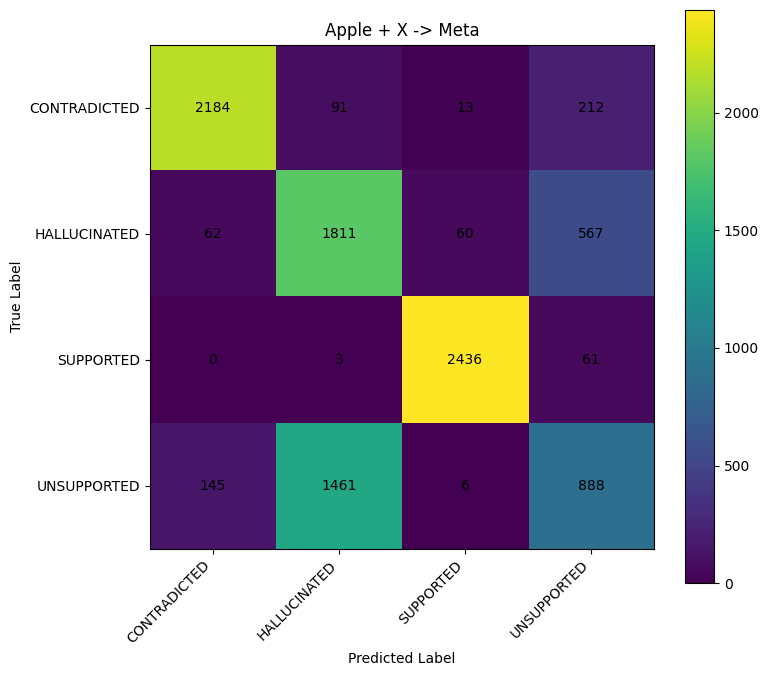


Errors: 2681 / 10000


##########################################################################################
Apple + Meta -> X
##########################################################################################

TRAIN DOMAINS : Apple + Meta
TEST DOMAIN   : X
Train samples : 20000
Test samples  : 10000

Training XGBoost...

RESULTS
------------------------------------------------------------
Accuracy            : 0.7440
Balanced Accuracy   : 0.7440
Macro Precision     : 0.7354
Macro Recall        : 0.7440
Macro F1            : 0.7387
Weighted F1         : 0.7387
Log Loss            : 0.6870

Classification Report:

              precision    recall  f1-score   support

CONTRADICTED     0.8998    0.9056    0.9027      2500
HALLUCINATED     0.5823    0.6096    0.5957      2500
   SUPPORTED     0.9307    0.9992    0.9637      2500
 UNSUPPORTED     0.5286    0.4616    0.4928      2500

    accuracy                         0.7440     10000
   macro avg     0.7354    0.7440    0.

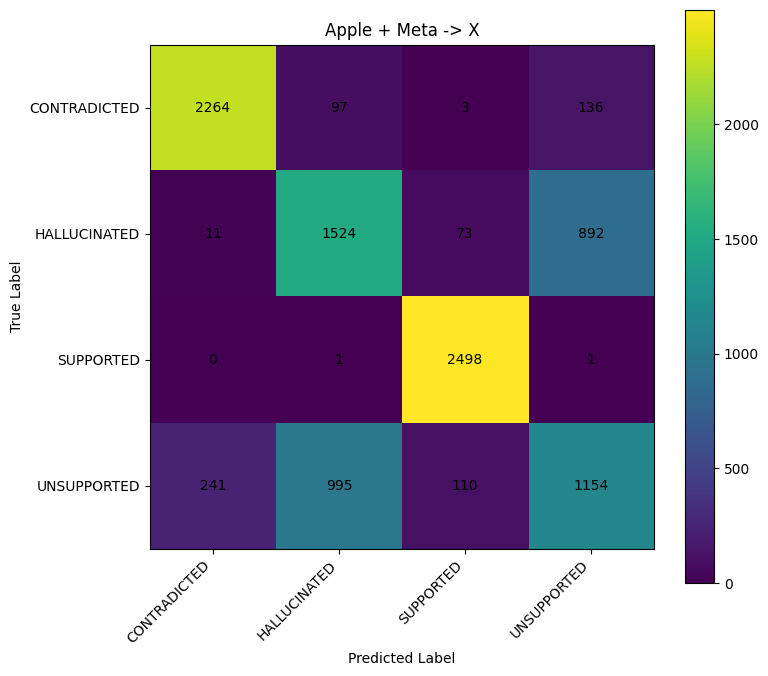


Errors: 2560 / 10000


##########################################################################################
X + Meta -> Apple
##########################################################################################

TRAIN DOMAINS : X + Meta
TEST DOMAIN   : Apple
Train samples : 20000
Test samples  : 10000

Training XGBoost...

RESULTS
------------------------------------------------------------
Accuracy            : 0.6980
Balanced Accuracy   : 0.6980
Macro Precision     : 0.6824
Macro Recall        : 0.6980
Macro F1            : 0.6763
Weighted F1         : 0.6763
Log Loss            : 1.1408

Classification Report:

              precision    recall  f1-score   support

CONTRADICTED     0.7118    0.9900    0.8282      2500
HALLUCINATED     0.5270    0.2968    0.3797      2500
   SUPPORTED     0.9992    0.9832    0.9911      2500
 UNSUPPORTED     0.4915    0.5220    0.5063      2500

    accuracy                         0.6980     10000
   macro avg     0.6824    0.6980    0.

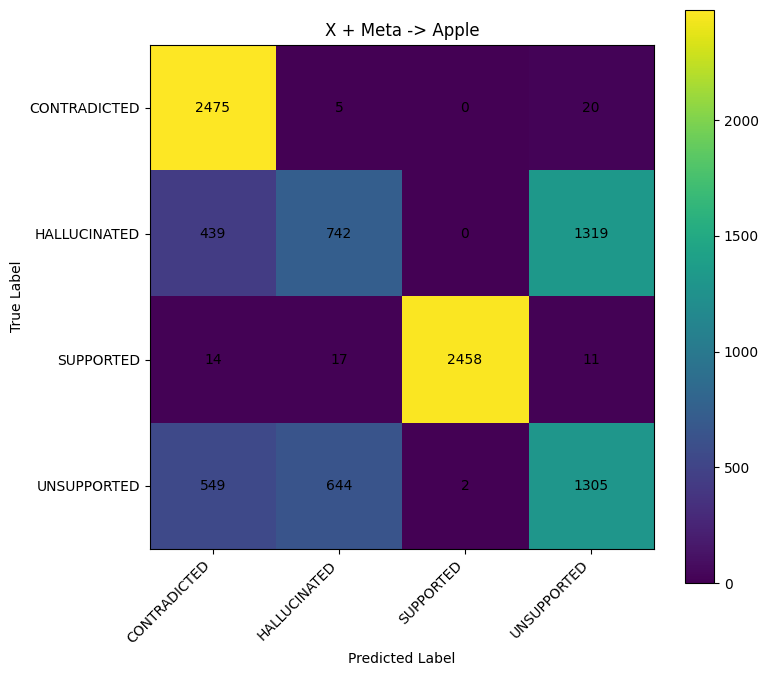


Errors: 3020 / 10000


FINAL CROSS-DOMAIN RESULTS


,experiment,train_domains,test_domain,train_size,test_size,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,log_loss,errors
0,Apple + X -> Meta,Apple + X,Meta,20000,10000,0.7319,0.7319,0.733483,0.7319,0.725517,0.725517,0.780204,2681
1,Apple + Meta -> X,Apple + Meta,X,20000,10000,0.7440,0.7440,0.735379,0.7440,0.738738,0.738738,0.686966,2560
2,X + Meta -> Apple,X + Meta,Apple,20000,10000,0.6980,0.6980,0.682380,0.6980,0.676336,0.676336,1.140813,3020




PAPER-READY TABLE
       experiment  train_size  test_size  accuracy  balanced_accuracy  macro_f1  weighted_f1  log_loss  errors
Apple + X -> Meta       20000      10000    0.7319             0.7319    0.7255       0.7255    0.7802    2681
Apple + Meta -> X       20000      10000    0.7440             0.7440    0.7387       0.7387    0.6870    2560
X + Meta -> Apple       20000      10000    0.6980             0.6980    0.6763       0.6763    1.1408    3020


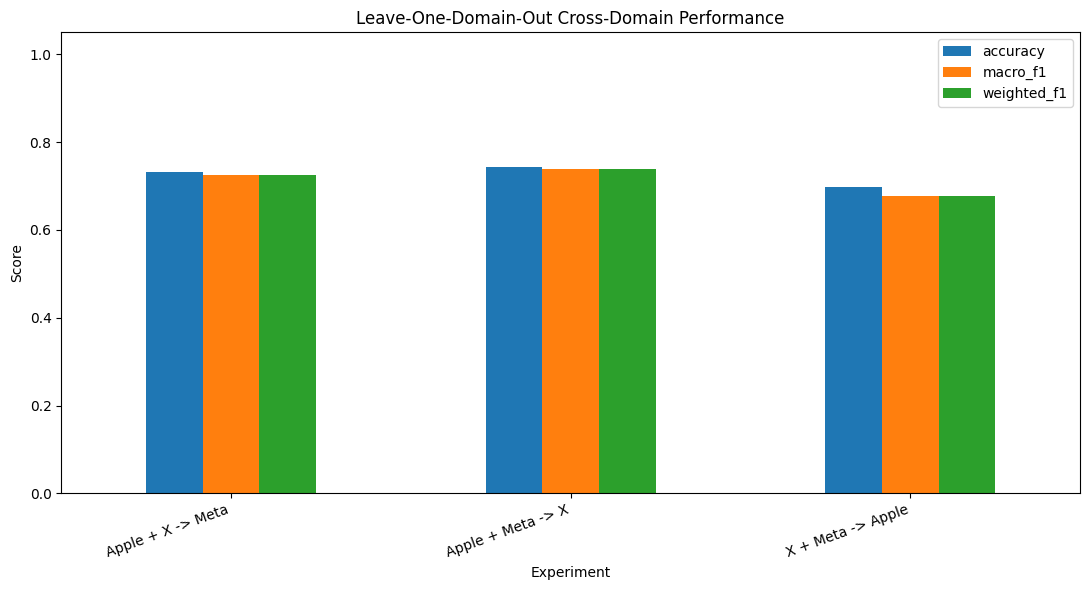



CROSS-DOMAIN EXPERIMENT COMPLETE

Apple + X -> Meta
  Accuracy : 0.7319
  Macro F1 : 0.7255
  Errors   : 2681

Apple + Meta -> X
  Accuracy : 0.7440
  Macro F1 : 0.7387
  Errors   : 2560

X + Meta -> Apple
  Accuracy : 0.6980
  Macro F1 : 0.6763
  Errors   : 3020

Results saved to:
contextual_hallucination_detector_final/cross_domain_experiments


In [22]:
# ============================================================
# CROSS-DOMAIN LEAVE-ONE-DOMAIN-OUT EXPERIMENT
#
# Experiment 1: Apple + X    -> Meta
# Experiment 2: Apple + Meta -> X
# Experiment 3: X + Meta     -> Apple
#
# IMPORTANT:
# This code assumes that your existing CHD notebook already has:
#   - feature extraction function
#   - semantic model loaded
#   - NLI model loaded
#
# All 3 datasets must have the same 13-column structure.
# ============================================================

import os
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    log_loss
)

from xgboost import XGBClassifier


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEEDS = [13, 21, 42, 77, 100]
OUTPUT_DIR = Path(
    "contextual_hallucination_detector_final/cross_domain_experiments"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# UPDATE THESE PATHS IF NECESSARY
# ------------------------------------------------------------

APPLE_PATH = "apple_privacy_hallucination_10000.csv"

X_PATH = (
    "x_privacy_policy_10000.csv"
)

META_PATH = (
    "meta_human_rights_policy_10000.csv"
)


# ============================================================
# 2. FEATURE NAMES
# ============================================================

FEATURE_NAMES = [
    "semantic_similarity",
    "lexical_overlap",
    "context_coverage",
    "entity_consistency",
    "number_consistency",
    "entailment",
    "contradiction",
    "neutral",
    "lexical_contradiction",
    "claim_length",
    "context_length",
    "claim_context_ratio",
]


LABEL_ORDER = [
    "CONTRADICTED",
    "HALLUCINATED",
    "SUPPORTED",
    "UNSUPPORTED",
]


# ============================================================
# 3. LOAD DATASETS
# ============================================================

apple_df = pd.read_csv(APPLE_PATH)
x_df = pd.read_csv(X_PATH)
meta_df = pd.read_csv(META_PATH)


print("=" * 80)
print("CROSS-DOMAIN DATASETS")
print("=" * 80)

print(f"\nApple: {apple_df.shape}")
print(f"X:     {x_df.shape}")
print(f"Meta:  {meta_df.shape}")


# ============================================================
# 4. BASIC CLEANING
# ============================================================

def clean_dataset(df, domain_name):

    df = df.copy()

    required_columns = [
        "context",
        "claim",
        "label",
    ]

    missing_columns = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{domain_name} is missing columns: {missing_columns}"
        )

    # Remove missing values
    df = df.dropna(
        subset=[
            "context",
            "claim",
            "label",
        ]
    ).copy()

    # Convert to string
    df["context"] = (
        df["context"]
        .astype(str)
        .str.strip()
    )

    df["claim"] = (
        df["claim"]
        .astype(str)
        .str.strip()
    )

    df["label"] = (
        df["label"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    # Remove empty texts
    df = df[
        (df["context"].str.len() > 0)
        &
        (df["claim"].str.len() > 0)
    ].copy()

    # Only valid CHD labels
    df = df[
        df["label"].isin(LABEL_ORDER)
    ].copy()

    df["domain"] = domain_name

    df = df.reset_index(drop=True)

    return df


apple_df = clean_dataset(
    apple_df,
    "Apple"
)

x_df = clean_dataset(
    x_df,
    "X"
)

meta_df = clean_dataset(
    meta_df,
    "Meta"
)


# ============================================================
# 5. CHECK LABEL DISTRIBUTION
# ============================================================

def print_distribution(df, name):

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Rows:", len(df))

    print(
        df["label"]
        .value_counts()
        .reindex(LABEL_ORDER)
    )


print_distribution(
    apple_df,
    "APPLE"
)

print_distribution(
    x_df,
    "X"
)

print_distribution(
    meta_df,
    "META"
)


# ============================================================
# 6. GLOBAL LABEL ENCODER
# ============================================================

label_encoder = LabelEncoder()

label_encoder.fit(
    LABEL_ORDER
)

print("\nLabel mapping:")

for i, cls in enumerate(label_encoder.classes_):
    print(
        f"{i} -> {cls}"
    )


# ============================================================
# 7. FEATURE EXTRACTION WRAPPER
# ============================================================
#
# IMPORTANT:
#
# Replace ONLY the content of this function if the name of your
# existing feature extraction function is different.
#
# Your existing notebook should already have a function that
# converts:
#
#       contexts + claims
#
# into the 12 CHD features.
#
# For example, if your existing function is:
#
#     create_features(df)
#
# simply use:
#
#     return create_features(df)
#
# ============================================================

# ============================================================
# FEATURE EXTRACTION WRAPPER — FIXED FOR YOUR NOTEBOOK
# ============================================================

def get_chd_features(df, dataset_name="dataset"):

    print("\n" + "=" * 80)
    print(f"CREATING FEATURES: {dataset_name}")
    print("=" * 80)

    contexts = df["context"].fillna("").astype(str).tolist()
    claims = df["claim"].fillna("").astype(str).tolist()

    X_features = compute_features(
        contexts,
        claims,
        batch_size=64,
        nli_batch_size=32
    )

    X_features = np.asarray(
        X_features,
        dtype=np.float32
    )

    print(f"\n{dataset_name} feature matrix shape: {X_features.shape}")

    if X_features.shape[1] != len(FEATURE_NAMES):
        raise ValueError(
            f"Expected {len(FEATURE_NAMES)} features, "
            f"but received {X_features.shape[1]}"
        )

    return X_features
# ============================================================
# 8. EXTRACT FEATURES ONCE
# ============================================================
#
# This is important:
# we do NOT recompute Apple/X/Meta features for each experiment.
# ============================================================

X_apple = get_chd_features(
    apple_df,
    "APPLE"
)

X_x = get_chd_features(
    x_df,
    "X"
)

X_meta = get_chd_features(
    meta_df,
    "META"
)


y_apple = label_encoder.transform(
    apple_df["label"]
)

y_x = label_encoder.transform(
    x_df["label"]
)

y_meta = label_encoder.transform(
    meta_df["label"]
)


print("\nFinal feature shapes:")

print(
    "Apple:",
    X_apple.shape
)

print(
    "X:",
    X_x.shape
)

print(
    "Meta:",
    X_meta.shape
)


# ============================================================
# 9. XGBOOST CONFIG
# ============================================================

def create_xgb_model(seed=42):

    return XGBClassifier(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="multi:softprob",
        num_class=4,
        eval_metric="mlogloss",
        random_state=seed,
        n_jobs=-1,
    )

# ============================================================
# 10. EVALUATION FUNCTION
# ============================================================

def evaluate_cross_domain(
    experiment_name,
    train_domains,
    test_domain,
    X_train,
    y_train,
    X_test,
    y_test,
    test_dataframe
):

    print("\n")
    print("#" * 90)
    print(experiment_name)
    print("#" * 90)

    print(
        f"\nTRAIN DOMAINS : {train_domains}"
    )

    print(
        f"TEST DOMAIN   : {test_domain}"
    )

    print(
        f"Train samples : {len(y_train)}"
    )

    print(
        f"Test samples  : {len(y_test)}"
    )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    model = create_xgb_model()

    print("\nTraining XGBoost...")

    model.fit(
        X_train,
        y_train
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred
    )

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    precision_weighted, recall_weighted, f1_weighted, _ = (
        precision_recall_fscore_support(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    try:

        test_logloss = log_loss(
            y_test,
            y_prob,
            labels=np.arange(
                len(label_encoder.classes_)
            )
        )

    except Exception:

        test_logloss = np.nan


    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    print("\nRESULTS")
    print("-" * 60)

    print(
        f"Accuracy            : "
        f"{accuracy:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{balanced_acc:.4f}"
    )

    print(
        f"Macro Precision     : "
        f"{precision_macro:.4f}"
    )

    print(
        f"Macro Recall        : "
        f"{recall_macro:.4f}"
    )

    print(
        f"Macro F1            : "
        f"{f1_macro:.4f}"
    )

    print(
        f"Weighted F1         : "
        f"{f1_weighted:.4f}"
    )

    print(
        f"Log Loss            : "
        f"{test_logloss:.4f}"
    )


    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(
                len(label_encoder.classes_)
            ),
            target_names=label_encoder.classes_,
            digits=4,
            zero_division=0
        )
    )


    # --------------------------------------------------------
    # Per-class results
    # --------------------------------------------------------

    report_dict = classification_report(
        y_test,
        y_pred,
        labels=np.arange(
            len(label_encoder.classes_)
        ),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0
    )

    per_class_rows = []

    for label in label_encoder.classes_:

        values = report_dict[label]

        per_class_rows.append({

            "experiment":
                experiment_name,

            "train_domains":
                train_domains,

            "test_domain":
                test_domain,

            "label":
                label,

            "precision":
                values["precision"],

            "recall":
                values["recall"],

            "f1":
                values["f1-score"],

            "support":
                values["support"],

        })

    per_class_df = pd.DataFrame(
        per_class_rows
    )


    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(
            len(label_encoder.classes_)
        )
    )

    cm_df = pd.DataFrame(
        cm,
        index=label_encoder.classes_,
        columns=label_encoder.classes_
    )

    print("\nConfusion Matrix:\n")
    print(cm_df)


    # Save CSV
    safe_name = (
        experiment_name
        .lower()
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("→", "to")
        .replace("->", "to")
    )

    cm_df.to_csv(
        OUTPUT_DIR /
        f"{safe_name}_confusion_matrix.csv"
    )


    # Save PNG
    fig, ax = plt.subplots(
        figsize=(8, 7)
    )

    im = ax.imshow(cm)

    ax.set_xticks(
        np.arange(
            len(label_encoder.classes_)
        )
    )

    ax.set_yticks(
        np.arange(
            len(label_encoder.classes_)
        )
    )

    ax.set_xticklabels(
        label_encoder.classes_,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(
        label_encoder.classes_
    )

    ax.set_xlabel(
        "Predicted Label"
    )

    ax.set_ylabel(
        "True Label"
    )

    ax.set_title(
        experiment_name
    )

    for i in range(cm.shape[0]):

        for j in range(cm.shape[1]):

            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center"
            )

    fig.colorbar(
        im,
        ax=ax
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR /
        f"{safe_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    predictions = test_dataframe.copy()

    predictions["true_label"] = (
        label_encoder.inverse_transform(
            y_test
        )
    )

    predictions["predicted_label"] = (
        label_encoder.inverse_transform(
            y_pred.astype(int)
        )
    )

    predictions["correct"] = (
        predictions["true_label"]
        ==
        predictions["predicted_label"]
    )

    predictions["confidence"] = (
        np.max(
            y_prob,
            axis=1
        )
    )


    for class_index, class_name in enumerate(
        label_encoder.classes_
    ):

        predictions[
            f"prob_{class_name}"
        ] = y_prob[:, class_index]


    predictions.to_csv(
        OUTPUT_DIR /
        f"{safe_name}_predictions.csv",
        index=False
    )


    # --------------------------------------------------------
    # Error file
    # --------------------------------------------------------

    errors = predictions[
        ~predictions["correct"]
    ].copy()

    errors.to_csv(
        OUTPUT_DIR /
        f"{safe_name}_errors.csv",
        index=False
    )


    print(
        f"\nErrors: "
        f"{len(errors)} / {len(y_test)}"
    )


    # --------------------------------------------------------
    # Global result
    # --------------------------------------------------------

    result = {

        "experiment":
            experiment_name,

        "train_domains":
            train_domains,

        "test_domain":
            test_domain,

        "train_size":
            len(y_train),

        "test_size":
            len(y_test),

        "accuracy":
            accuracy,

        "balanced_accuracy":
            balanced_acc,

        "macro_precision":
            precision_macro,

        "macro_recall":
            recall_macro,

        "macro_f1":
            f1_macro,

        "weighted_f1":
            f1_weighted,

        "log_loss":
            test_logloss,

        "errors":
            len(errors),

    }

    return (
        result,
        per_class_df,
        model
    )


# ============================================================
# 11. EXPERIMENT 1
#
# APPLE + X -> META
# ============================================================

X_train_1 = np.vstack([
    X_apple,
    X_x
])

y_train_1 = np.concatenate([
    y_apple,
    y_x
])


result_1, class_1, model_1 = (
    evaluate_cross_domain(

        experiment_name=
        "Apple + X -> Meta",

        train_domains=
        "Apple + X",

        test_domain=
        "Meta",

        X_train=
        X_train_1,

        y_train=
        y_train_1,

        X_test=
        X_meta,

        y_test=
        y_meta,

        test_dataframe=
        meta_df
    )
)


# ============================================================
# 12. EXPERIMENT 2
#
# APPLE + META -> X
# ============================================================

X_train_2 = np.vstack([
    X_apple,
    X_meta
])

y_train_2 = np.concatenate([
    y_apple,
    y_meta
])


result_2, class_2, model_2 = (
    evaluate_cross_domain(

        experiment_name=
        "Apple + Meta -> X",

        train_domains=
        "Apple + Meta",

        test_domain=
        "X",

        X_train=
        X_train_2,

        y_train=
        y_train_2,

        X_test=
        X_x,

        y_test=
        y_x,

        test_dataframe=
        x_df
    )
)


# ============================================================
# 13. EXPERIMENT 3
#
# X + META -> APPLE
# ============================================================

X_train_3 = np.vstack([
    X_x,
    X_meta
])

y_train_3 = np.concatenate([
    y_x,
    y_meta
])


result_3, class_3, model_3 = (
    evaluate_cross_domain(

        experiment_name=
        "X + Meta -> Apple",

        train_domains=
        "X + Meta",

        test_domain=
        "Apple",

        X_train=
        X_train_3,

        y_train=
        y_train_3,

        X_test=
        X_apple,

        y_test=
        y_apple,

        test_dataframe=
        apple_df
    )
)


# ============================================================
# 14. COMBINE GLOBAL RESULTS
# ============================================================

cross_domain_results = pd.DataFrame([
    result_1,
    result_2,
    result_3,
])


print("\n")
print("=" * 100)
print("FINAL CROSS-DOMAIN RESULTS")
print("=" * 100)

display(
    cross_domain_results
)


cross_domain_results.to_csv(
    OUTPUT_DIR /
    "cross_domain_summary.csv",
    index=False
)


# ============================================================
# 15. COMBINE PER-CLASS RESULTS
# ============================================================

all_class_results = pd.concat(
    [
        class_1,
        class_2,
        class_3,
    ],
    ignore_index=True
)


all_class_results.to_csv(
    OUTPUT_DIR /
    "cross_domain_per_class_results.csv",
    index=False
)


# ============================================================
# 16. COMPARISON TABLE
# ============================================================

comparison_table = (
    cross_domain_results[
        [
            "experiment",
            "train_size",
            "test_size",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "weighted_f1",
            "log_loss",
            "errors",
        ]
    ]
    .copy()
)


print("\n")
print("=" * 100)
print("PAPER-READY TABLE")
print("=" * 100)

print(
    comparison_table
    .round(4)
    .to_string(
        index=False
    )
)


comparison_table.to_csv(
    OUTPUT_DIR /
    "cross_domain_paper_table.csv",
    index=False
)


# ============================================================
# 17. PERFORMANCE BAR PLOT
# ============================================================

plot_df = (
    cross_domain_results
    .set_index("experiment")
    [
        [
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)


ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_ylabel(
    "Score"
)

ax.set_xlabel(
    "Experiment"
)

ax.set_ylim(
    0,
    1.05
)

ax.set_title(
    "Leave-One-Domain-Out Cross-Domain Performance"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "cross_domain_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 18. SAVE MODELS
# ============================================================

model_1.save_model(
    OUTPUT_DIR /
    "model_apple_x_to_meta.json"
)

model_2.save_model(
    OUTPUT_DIR /
    "model_apple_meta_to_x.json"
)

model_3.save_model(
    OUTPUT_DIR /
    "model_x_meta_to_apple.json"
)


# ============================================================
# 19. SAVE JSON SUMMARY
# ============================================================

json_results = []

for result in [
    result_1,
    result_2,
    result_3,
]:

    clean_result = {}

    for key, value in result.items():

        if isinstance(
            value,
            (np.integer,)
        ):

            value = int(value)

        elif isinstance(
            value,
            (np.floating,)
        ):

            value = float(value)

        clean_result[key] = value

    json_results.append(
        clean_result
    )


with open(
    OUTPUT_DIR /
    "cross_domain_results.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        json_results,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 100)
print("CROSS-DOMAIN EXPERIMENT COMPLETE")
print("=" * 100)

for result in [
    result_1,
    result_2,
    result_3,
]:

    print(
        f"\n{result['experiment']}"
    )

    print(
        f"  Accuracy : "
        f"{result['accuracy']:.4f}"
    )

    print(
        f"  Macro F1 : "
        f"{result['macro_f1']:.4f}"
    )

    print(
        f"  Errors   : "
        f"{result['errors']}"
    )


print(
    "\nResults saved to:"
)

print(
    OUTPUT_DIR
)

In [ ]:
# multi seed 

CROSS-DOMAIN DATASETS

Apple: (10000, 13)
X:     (10000, 13)
Meta:  (10000, 13)

APPLE
Rows: 10000
label
CONTRADICTED    2500
HALLUCINATED    2500
SUPPORTED       2500
UNSUPPORTED     2500
Name: count, dtype: int64

X
Rows: 10000
label
CONTRADICTED    2500
HALLUCINATED    2500
SUPPORTED       2500
UNSUPPORTED     2500
Name: count, dtype: int64

META
Rows: 10000
label
CONTRADICTED    2500
HALLUCINATED    2500
SUPPORTED       2500
UNSUPPORTED     2500
Name: count, dtype: int64

Label mapping:
0 -> CONTRADICTED
1 -> HALLUCINATED
2 -> SUPPORTED
3 -> UNSUPPORTED

CREATING FEATURES: APPLE

Encoding 10000 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:04<00:00, 33.57it/s]


Computing batched NLI probabilities...

APPLE feature matrix shape: (10000, 12)

CREATING FEATURES: X

Encoding 10000 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:04<00:00, 38.99it/s]


Computing batched NLI probabilities...

X feature matrix shape: (10000, 12)

CREATING FEATURES: META

Encoding 10000 examples...


Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 157/157 [00:03<00:00, 40.04it/s]


... (9 outputs left out)

,experiment,train_domains,test_domain,train_size,test_size,n_seeds,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,...,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,log_loss_mean,log_loss_std,errors_mean,errors_std
0,Apple + X -> Meta,Apple + X,Meta,20000,10000,5,0.7305,0.0013,0.7305,0.0013,...,0.7305,0.0013,0.7243,0.0011,0.7243,0.0011,0.7893,0.0112,2695.2,12.9885
1,Apple + Meta -> X,Apple + Meta,X,20000,10000,5,0.7453,0.0018,0.7453,0.0018,...,0.7453,0.0018,0.7402,0.0018,0.7402,0.0018,0.6810,0.0035,2547.0,18.0555
2,X + Meta -> Apple,X + Meta,Apple,20000,10000,5,0.7001,0.0031,0.7001,0.0031,...,0.7001,0.0031,0.6789,0.0042,0.6789,0.0042,1.1407,0.0088,2998.8,31.4754




PER-CLASS MULTI-SEED RESULTS


,experiment,train_domains,test_domain,label,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,support
0,Apple + X -> Meta,Apple + X,Meta,CONTRADICTED,0.9094,0.0052,0.8713,0.0025,0.8899,0.0024,2500.0
1,Apple + X -> Meta,Apple + X,Meta,HALLUCINATED,0.5382,0.0024,0.7194,0.0069,0.6157,0.0027,2500.0
2,Apple + X -> Meta,Apple + X,Meta,SUPPORTED,0.9683,0.0006,0.9740,0.0007,0.9712,0.0005,2500.0
3,Apple + X -> Meta,Apple + X,Meta,UNSUPPORTED,0.5110,0.0043,0.3572,0.0028,0.4205,0.0022,2500.0
4,Apple + Meta -> X,Apple + Meta,X,CONTRADICTED,0.9013,0.0014,0.9062,0.0031,0.9037,0.0012,2500.0
5,Apple + Meta -> X,Apple + Meta,X,HALLUCINATED,0.5842,0.0027,0.6090,0.0045,0.5963,0.0033,2500.0
6,Apple + Meta -> X,Apple + Meta,X,SUPPORTED,0.9311,0.0015,0.9991,0.0002,0.9639,0.0008,2500.0
7,Apple + Meta -> X,Apple + Meta,X,UNSUPPORTED,0.5311,0.0044,0.4669,0.0042,0.4969,0.0035,2500.0
8,X + Meta -> Apple,X + Meta,Apple,CONTRADICTED,0.7114,0.0018,0.9891,0.0009,0.8276,0.0013,2500.0
9,X + Meta -> Apple,X + Meta,Apple,HALLUCINATED,0.5348,0.0098,0.3032,0.0157,0.3869,0.0152,2500.0




PAPER-READY MULTI-SEED TABLE
       Experiment        Train  Test        Accuracy Balanced Accuracy Macro Precision    Macro Recall        Macro F1     Weighted F1        Log Loss
Apple + X -> Meta    Apple + X  Meta 0.7305 ± 0.0013   0.7305 ± 0.0013 0.7317 ± 0.0017 0.7305 ± 0.0013 0.7243 ± 0.0011 0.7243 ± 0.0011 0.7893 ± 0.0112
Apple + Meta -> X Apple + Meta     X 0.7453 ± 0.0018   0.7453 ± 0.0018 0.7369 ± 0.0018 0.7453 ± 0.0018 0.7402 ± 0.0018 0.7402 ± 0.0018 0.6810 ± 0.0035
X + Meta -> Apple     X + Meta Apple 0.7001 ± 0.0031   0.7001 ± 0.0031 0.6854 ± 0.0039 0.7001 ± 0.0031 0.6789 ± 0.0042 0.6789 ± 0.0042 1.1407 ± 0.0088


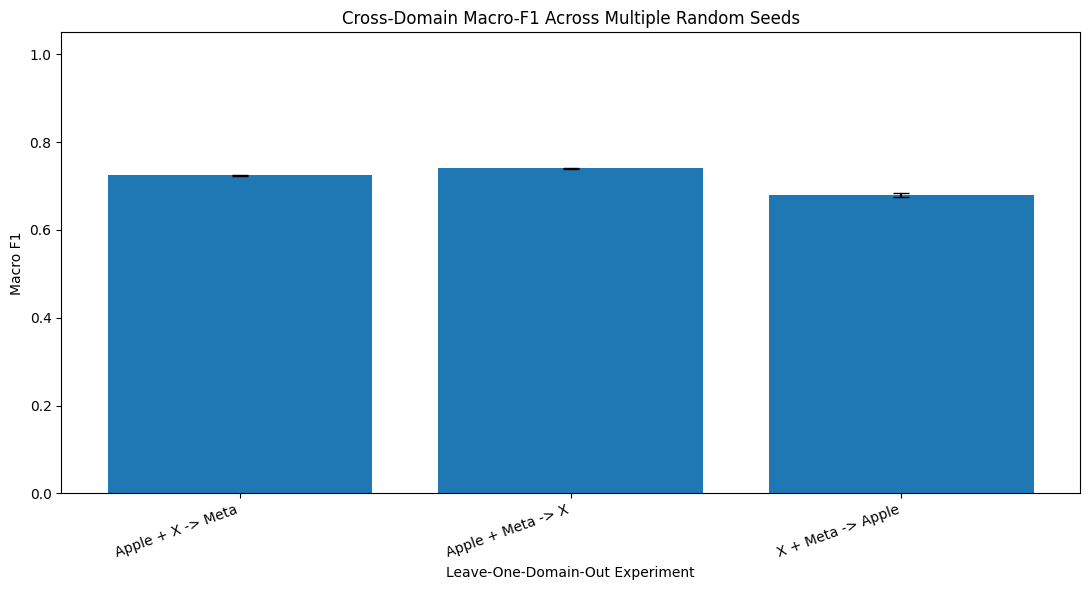

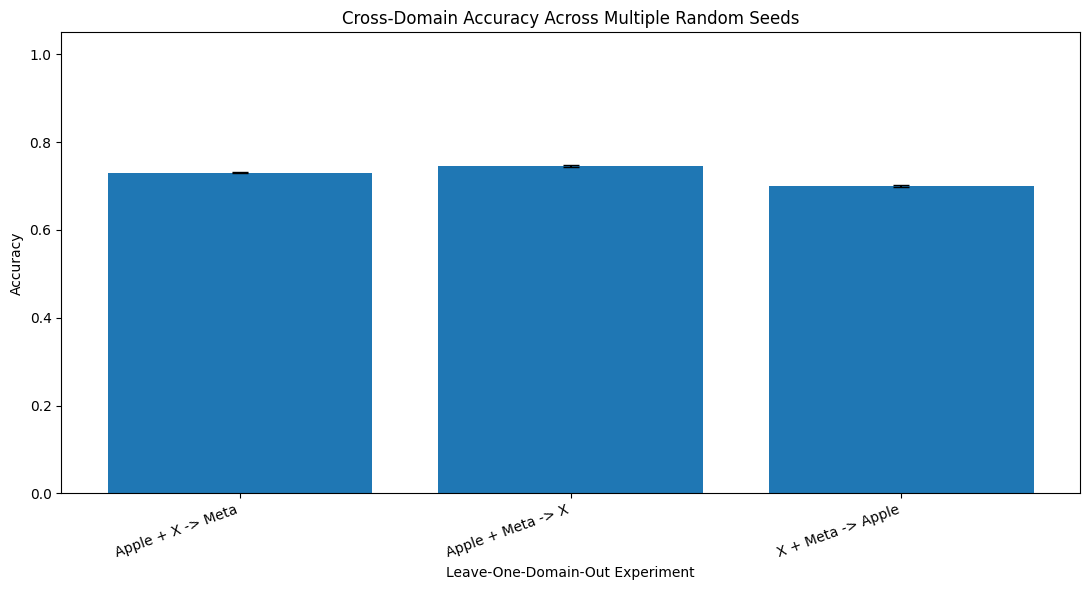



OVERALL CROSS-DOMAIN PERFORMANCE
Mean Accuracy          : 0.7253
Mean Balanced Accuracy : 0.7253
Mean Macro F1          : 0.7145
Mean Weighted F1       : 0.7145
Mean Log Loss          : 0.8704


MULTI-SEED CROSS-DOMAIN EXPERIMENT COMPLETE

Apple + X -> Meta
  Accuracy : 0.7305 ± 0.0013
  Macro F1 : 0.7243 ± 0.0011
  Log Loss : 0.7893 ± 0.0112

Apple + Meta -> X
  Accuracy : 0.7453 ± 0.0018
  Macro F1 : 0.7402 ± 0.0018
  Log Loss : 0.6810 ± 0.0035

X + Meta -> Apple
  Accuracy : 0.7001 ± 0.0031
  Macro F1 : 0.6789 ± 0.0042
  Log Loss : 1.1407 ± 0.0088

Overall:
  Accuracy : 0.7253
  Macro F1 : 0.7145

Results saved to:
contextual_hallucination_detector_final/cross_domain_experiments


In [23]:
# ============================================================
# CROSS-DOMAIN LEAVE-ONE-DOMAIN-OUT EXPERIMENT
#
# Experiment 1: Apple + X    -> Meta
# Experiment 2: Apple + Meta -> X
# Experiment 3: X + Meta     -> Apple
#
# IMPORTANT:
# This code assumes that your existing CHD notebook already has:
#   - feature extraction function
#   - semantic model loaded
#   - NLI model loaded
#
# All 3 datasets must have the same 13-column structure.
# ============================================================

import os
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    log_loss
)

from xgboost import XGBClassifier


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEEDS = [13, 21, 42, 77, 100]
OUTPUT_DIR = Path(
    "contextual_hallucination_detector_final/cross_domain_experiments"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# UPDATE THESE PATHS IF NECESSARY
# ------------------------------------------------------------

APPLE_PATH = "apple_privacy_hallucination_10000.csv"

X_PATH = (
    "x_privacy_policy_10000.csv"
)

META_PATH = (
    "meta_human_rights_policy_10000.csv"
)


# ============================================================
# 2. FEATURE NAMES
# ============================================================

FEATURE_NAMES = [
    "semantic_similarity",
    "lexical_overlap",
    "context_coverage",
    "entity_consistency",
    "number_consistency",
    "entailment",
    "contradiction",
    "neutral",
    "lexical_contradiction",
    "claim_length",
    "context_length",
    "claim_context_ratio",
]


LABEL_ORDER = [
    "CONTRADICTED",
    "HALLUCINATED",
    "SUPPORTED",
    "UNSUPPORTED",
]


# ============================================================
# 3. LOAD DATASETS
# ============================================================

apple_df = pd.read_csv(APPLE_PATH)
x_df = pd.read_csv(X_PATH)
meta_df = pd.read_csv(META_PATH)


print("=" * 80)
print("CROSS-DOMAIN DATASETS")
print("=" * 80)

print(f"\nApple: {apple_df.shape}")
print(f"X:     {x_df.shape}")
print(f"Meta:  {meta_df.shape}")


# ============================================================
# 4. BASIC CLEANING
# ============================================================

def clean_dataset(df, domain_name):

    df = df.copy()

    required_columns = [
        "context",
        "claim",
        "label",
    ]

    missing_columns = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{domain_name} is missing columns: {missing_columns}"
        )

    # Remove missing values
    df = df.dropna(
        subset=[
            "context",
            "claim",
            "label",
        ]
    ).copy()

    # Convert to string
    df["context"] = (
        df["context"]
        .astype(str)
        .str.strip()
    )

    df["claim"] = (
        df["claim"]
        .astype(str)
        .str.strip()
    )

    df["label"] = (
        df["label"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    # Remove empty texts
    df = df[
        (df["context"].str.len() > 0)
        &
        (df["claim"].str.len() > 0)
    ].copy()

    # Only valid CHD labels
    df = df[
        df["label"].isin(LABEL_ORDER)
    ].copy()

    df["domain"] = domain_name

    df = df.reset_index(drop=True)

    return df


apple_df = clean_dataset(
    apple_df,
    "Apple"
)

x_df = clean_dataset(
    x_df,
    "X"
)

meta_df = clean_dataset(
    meta_df,
    "Meta"
)


# ============================================================
# 5. CHECK LABEL DISTRIBUTION
# ============================================================

def print_distribution(df, name):

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Rows:", len(df))

    print(
        df["label"]
        .value_counts()
        .reindex(LABEL_ORDER)
    )


print_distribution(
    apple_df,
    "APPLE"
)

print_distribution(
    x_df,
    "X"
)

print_distribution(
    meta_df,
    "META"
)


# ============================================================
# 6. GLOBAL LABEL ENCODER
# ============================================================

label_encoder = LabelEncoder()

label_encoder.fit(
    LABEL_ORDER
)

print("\nLabel mapping:")

for i, cls in enumerate(label_encoder.classes_):
    print(
        f"{i} -> {cls}"
    )


# ============================================================
# 7. FEATURE EXTRACTION WRAPPER
# ============================================================
#
# IMPORTANT:
#
# Replace ONLY the content of this function if the name of your
# existing feature extraction function is different.
#
# Your existing notebook should already have a function that
# converts:
#
#       contexts + claims
#
# into the 12 CHD features.
#
# For example, if your existing function is:
#
#     create_features(df)
#
# simply use:
#
#     return create_features(df)
#
# ============================================================

# ============================================================
# FEATURE EXTRACTION WRAPPER — FIXED FOR YOUR NOTEBOOK
# ============================================================

def get_chd_features(df, dataset_name="dataset"):

    print("\n" + "=" * 80)
    print(f"CREATING FEATURES: {dataset_name}")
    print("=" * 80)

    contexts = df["context"].fillna("").astype(str).tolist()
    claims = df["claim"].fillna("").astype(str).tolist()

    X_features = compute_features(
        contexts,
        claims,
        batch_size=64,
        nli_batch_size=32
    )

    X_features = np.asarray(
        X_features,
        dtype=np.float32
    )

    print(f"\n{dataset_name} feature matrix shape: {X_features.shape}")

    if X_features.shape[1] != len(FEATURE_NAMES):
        raise ValueError(
            f"Expected {len(FEATURE_NAMES)} features, "
            f"but received {X_features.shape[1]}"
        )

    return X_features
# ============================================================
# 8. EXTRACT FEATURES ONCE
# ============================================================
#
# This is important:
# we do NOT recompute Apple/X/Meta features for each experiment.
# ============================================================

X_apple = get_chd_features(
    apple_df,
    "APPLE"
)

X_x = get_chd_features(
    x_df,
    "X"
)

X_meta = get_chd_features(
    meta_df,
    "META"
)


y_apple = label_encoder.transform(
    apple_df["label"]
)

y_x = label_encoder.transform(
    x_df["label"]
)

y_meta = label_encoder.transform(
    meta_df["label"]
)


print("\nFinal feature shapes:")

print(
    "Apple:",
    X_apple.shape
)

print(
    "X:",
    X_x.shape
)

print(
    "Meta:",
    X_meta.shape
)


# ============================================================
# 9. XGBOOST CONFIG
# ============================================================
# ============================================================
# 9. MULTI-SEED XGBOOST CONFIG
# ============================================================

# Keep these seeds fixed for reproducibility
SEEDS = [13, 21, 42, 77, 100]

print("\nMulti-seed configuration:")
print("SEEDS =", SEEDS)


def create_xgb_model(seed=42):
    """
    Create the same XGBoost configuration used in the CHD pipeline,
    while allowing the random seed to vary across runs.
    """

    return XGBClassifier(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=seed,
        n_jobs=-1,
    )


# ============================================================
# 10. HELPER FUNCTIONS
# ============================================================

def safe_experiment_name(name):
    """
    Convert experiment name into a safe filename.
    """

    return (
        name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("→", "to")
        .replace("->", "to")
        .replace("/", "_")
    )


def calculate_metrics(y_true, y_pred, y_prob):
    """
    Calculate global evaluation metrics.
    """

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    precision_weighted, recall_weighted, f1_weighted, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    try:
        test_logloss = log_loss(
            y_true,
            y_prob,
            labels=np.arange(
                len(label_encoder.classes_)
            )
        )
    except Exception:
        test_logloss = np.nan

    return {
        "accuracy": accuracy,
        "balanced_accuracy": balanced_acc,
        "macro_precision": precision_macro,
        "macro_recall": recall_macro,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted,
        "log_loss": test_logloss,
    }


# ============================================================
# 11. SINGLE-SEED EVALUATION FUNCTION
# ============================================================

def evaluate_single_seed(
    experiment_name,
    train_domains,
    test_domain,
    X_train,
    y_train,
    X_test,
    y_test,
    test_dataframe,
    seed
):

    print("\n" + "#" * 90)
    print(
        f"{experiment_name} | SEED = {seed}"
    )
    print("#" * 90)

    print(
        f"Train domains : {train_domains}"
    )

    print(
        f"Test domain   : {test_domain}"
    )

    print(
        f"Train samples : {len(y_train)}"
    )

    print(
        f"Test samples  : {len(y_test)}"
    )

    # --------------------------------------------------------
    # Train model
    # --------------------------------------------------------

    model = create_xgb_model(
        seed=seed
    )

    print("\nTraining XGBoost...")

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test
    ).astype(int)

    y_prob = model.predict_proba(
        X_test
    )

    # --------------------------------------------------------
    # Global metrics
    # --------------------------------------------------------

    metrics = calculate_metrics(
        y_test,
        y_pred,
        y_prob
    )

    errors_count = int(
        np.sum(
            y_pred != y_test
        )
    )

    result = {
        "experiment": experiment_name,
        "train_domains": train_domains,
        "test_domain": test_domain,
        "seed": seed,
        "train_size": len(y_train),
        "test_size": len(y_test),

        **metrics,

        "errors": errors_count,
    }

    # --------------------------------------------------------
    # Print metrics
    # --------------------------------------------------------

    print("\nRESULTS")
    print("-" * 60)

    print(
        f"Accuracy            : "
        f"{metrics['accuracy']:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro Precision     : "
        f"{metrics['macro_precision']:.4f}"
    )

    print(
        f"Macro Recall        : "
        f"{metrics['macro_recall']:.4f}"
    )

    print(
        f"Macro F1            : "
        f"{metrics['macro_f1']:.4f}"
    )

    print(
        f"Weighted F1         : "
        f"{metrics['weighted_f1']:.4f}"
    )

    print(
        f"Log Loss            : "
        f"{metrics['log_loss']:.4f}"
    )

    print(
        f"Errors              : "
        f"{errors_count}"
    )

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(
                len(label_encoder.classes_)
            ),
            target_names=label_encoder.classes_,
            digits=4,
            zero_division=0
        )
    )

    report_dict = classification_report(
        y_test,
        y_pred,
        labels=np.arange(
            len(label_encoder.classes_)
        ),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0
    )

    # --------------------------------------------------------
    # Per-class results
    # --------------------------------------------------------

    per_class_rows = []

    for label in label_encoder.classes_:

        values = report_dict[label]

        per_class_rows.append({
            "experiment": experiment_name,
            "train_domains": train_domains,
            "test_domain": test_domain,
            "seed": seed,
            "label": label,
            "precision": values["precision"],
            "recall": values["recall"],
            "f1": values["f1-score"],
            "support": values["support"],
        })

    per_class_df = pd.DataFrame(
        per_class_rows
    )

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(
            len(label_encoder.classes_)
        )
    )

    cm_df = pd.DataFrame(
        cm,
        index=label_encoder.classes_,
        columns=label_encoder.classes_
    )

    print("\nConfusion Matrix:\n")
    print(cm_df)

    # --------------------------------------------------------
    # Output folders
    # --------------------------------------------------------

    safe_name = safe_experiment_name(
        experiment_name
    )

    experiment_dir = (
        OUTPUT_DIR /
        safe_name
    )

    experiment_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    seed_dir = (
        experiment_dir /
        f"seed_{seed}"
    )

    seed_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Save confusion matrix CSV
    # --------------------------------------------------------

    cm_df.to_csv(
        seed_dir /
        "confusion_matrix.csv"
    )

    # --------------------------------------------------------
    # Save confusion matrix PNG
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 7)
    )

    im = ax.imshow(
        cm
    )

    ax.set_xticks(
        np.arange(
            len(label_encoder.classes_)
        )
    )

    ax.set_yticks(
        np.arange(
            len(label_encoder.classes_)
        )
    )

    ax.set_xticklabels(
        label_encoder.classes_,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(
        label_encoder.classes_
    )

    ax.set_xlabel(
        "Predicted Label"
    )

    ax.set_ylabel(
        "True Label"
    )

    ax.set_title(
        f"{experiment_name}\nSeed = {seed}"
    )

    for i in range(
        cm.shape[0]
    ):
        for j in range(
            cm.shape[1]
        ):

            ax.text(
                j,
                i,
                str(
                    cm[i, j]
                ),
                ha="center",
                va="center"
            )

    fig.colorbar(
        im,
        ax=ax
    )

    plt.tight_layout()

    plt.savefig(
        seed_dir /
        "confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    predictions = (
        test_dataframe
        .copy()
        .reset_index(drop=True)
    )

    predictions["true_label"] = (
        label_encoder.inverse_transform(
            y_test.astype(int)
        )
    )

    predictions["predicted_label"] = (
        label_encoder.inverse_transform(
            y_pred
        )
    )

    predictions["correct"] = (
        predictions["true_label"]
        ==
        predictions["predicted_label"]
    )

    predictions["confidence"] = (
        np.max(
            y_prob,
            axis=1
        )
    )

    for class_index, class_name in enumerate(
        label_encoder.classes_
    ):

        predictions[
            f"prob_{class_name}"
        ] = y_prob[:, class_index]

    predictions.to_csv(
        seed_dir /
        "predictions.csv",
        index=False
    )

    # --------------------------------------------------------
    # Save errors
    # --------------------------------------------------------

    errors = predictions[
        ~predictions["correct"]
    ].copy()

    errors.to_csv(
        seed_dir /
        "errors.csv",
        index=False
    )

    # --------------------------------------------------------
    # Save model
    # --------------------------------------------------------

    model.save_model(
        str(
            seed_dir /
            "model.json"
        )
    )

    # --------------------------------------------------------
    # Save per-class result
    # --------------------------------------------------------

    per_class_df.to_csv(
        seed_dir /
        "per_class_results.csv",
        index=False
    )

    # --------------------------------------------------------
    # Save global result
    # --------------------------------------------------------

    pd.DataFrame(
        [result]
    ).to_csv(
        seed_dir /
        "global_results.csv",
        index=False
    )

    return (
        result,
        per_class_df,
        cm,
        model
    )


# ============================================================
# 12. MULTI-SEED EXPERIMENT FUNCTION
# ============================================================

def run_multiseed_experiment(
    experiment_name,
    train_domains,
    test_domain,
    X_train,
    y_train,
    X_test,
    y_test,
    test_dataframe
):

    print("\n")
    print("=" * 100)
    print(
        f"MULTI-SEED EXPERIMENT: {experiment_name}"
    )
    print("=" * 100)

    all_results = []
    all_class_results = []
    all_confusion_matrices = []
    models = {}

    for seed in SEEDS:

        (
            result,
            per_class_df,
            cm,
            model
        ) = evaluate_single_seed(

            experiment_name=
                experiment_name,

            train_domains=
                train_domains,

            test_domain=
                test_domain,

            X_train=
                X_train,

            y_train=
                y_train,

            X_test=
                X_test,

            y_test=
                y_test,

            test_dataframe=
                test_dataframe,

            seed=
                seed
        )

        all_results.append(
            result
        )

        all_class_results.append(
            per_class_df
        )

        all_confusion_matrices.append(
            cm
        )

        models[seed] = model

    # --------------------------------------------------------
    # Convert seed results to dataframe
    # --------------------------------------------------------

    seed_results_df = pd.DataFrame(
        all_results
    )

    per_class_seed_df = pd.concat(
        all_class_results,
        ignore_index=True
    )

    # --------------------------------------------------------
    # Metric summary: mean ± std
    # --------------------------------------------------------

    metric_columns = [
        "accuracy",
        "balanced_accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1",
        "log_loss",
        "errors",
    ]

    summary = {
        "experiment": experiment_name,
        "train_domains": train_domains,
        "test_domain": test_domain,
        "train_size": len(y_train),
        "test_size": len(y_test),
        "n_seeds": len(SEEDS),
    }

    for metric in metric_columns:

        summary[
            f"{metric}_mean"
        ] = seed_results_df[
            metric
        ].mean()

        summary[
            f"{metric}_std"
        ] = seed_results_df[
            metric
        ].std(
            ddof=1
        )

    summary_df = pd.DataFrame(
        [summary]
    )

    # --------------------------------------------------------
    # Per-class mean ± std
    # --------------------------------------------------------

    per_class_summary = (
        per_class_seed_df
        .groupby(
            [
                "experiment",
                "train_domains",
                "test_domain",
                "label"
            ],
            as_index=False
        )
        .agg(
            precision_mean=(
                "precision",
                "mean"
            ),
            precision_std=(
                "precision",
                "std"
            ),
            recall_mean=(
                "recall",
                "mean"
            ),
            recall_std=(
                "recall",
                "std"
            ),
            f1_mean=(
                "f1",
                "mean"
            ),
            f1_std=(
                "f1",
                "std"
            ),
            support=(
                "support",
                "first"
            )
        )
    )

    # --------------------------------------------------------
    # Aggregate confusion matrix
    # --------------------------------------------------------

    mean_cm = np.mean(
        np.stack(
            all_confusion_matrices,
            axis=0
        ),
        axis=0
    )

    mean_cm_df = pd.DataFrame(
        mean_cm,
        index=label_encoder.classes_,
        columns=label_encoder.classes_
    )

    # --------------------------------------------------------
    # Save experiment-level outputs
    # --------------------------------------------------------

    safe_name = safe_experiment_name(
        experiment_name
    )

    experiment_dir = (
        OUTPUT_DIR /
        safe_name
    )

    experiment_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    seed_results_df.to_csv(
        experiment_dir /
        "all_seed_results.csv",
        index=False
    )

    summary_df.to_csv(
        experiment_dir /
        "mean_std_summary.csv",
        index=False
    )

    per_class_seed_df.to_csv(
        experiment_dir /
        "all_seed_per_class_results.csv",
        index=False
    )

    per_class_summary.to_csv(
        experiment_dir /
        "per_class_mean_std.csv",
        index=False
    )

    mean_cm_df.to_csv(
        experiment_dir /
        "mean_confusion_matrix.csv"
    )

    # --------------------------------------------------------
    # Plot mean confusion matrix
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 7)
    )

    im = ax.imshow(
        mean_cm
    )

    ax.set_xticks(
        np.arange(
            len(label_encoder.classes_)
        )
    )

    ax.set_yticks(
        np.arange(
            len(label_encoder.classes_)
        )
    )

    ax.set_xticklabels(
        label_encoder.classes_,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(
        label_encoder.classes_
    )

    ax.set_xlabel(
        "Predicted Label"
    )

    ax.set_ylabel(
        "True Label"
    )

    ax.set_title(
        f"{experiment_name}\n"
        f"Mean Confusion Matrix Across {len(SEEDS)} Seeds"
    )

    for i in range(
        mean_cm.shape[0]
    ):
        for j in range(
            mean_cm.shape[1]
        ):

            ax.text(
                j,
                i,
                f"{mean_cm[i, j]:.1f}",
                ha="center",
                va="center"
            )

    fig.colorbar(
        im,
        ax=ax
    )

    plt.tight_layout()

    plt.savefig(
        experiment_dir /
        "mean_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # --------------------------------------------------------
    # Print summary
    # --------------------------------------------------------

    print("\n")
    print("=" * 90)
    print(
        f"MULTI-SEED SUMMARY: {experiment_name}"
    )
    print("=" * 90)

    print(
        f"Accuracy          : "
        f"{summary['accuracy_mean']:.4f} "
        f"± {summary['accuracy_std']:.4f}"
    )

    print(
        f"Balanced Accuracy : "
        f"{summary['balanced_accuracy_mean']:.4f} "
        f"± {summary['balanced_accuracy_std']:.4f}"
    )

    print(
        f"Macro Precision   : "
        f"{summary['macro_precision_mean']:.4f} "
        f"± {summary['macro_precision_std']:.4f}"
    )

    print(
        f"Macro Recall      : "
        f"{summary['macro_recall_mean']:.4f} "
        f"± {summary['macro_recall_std']:.4f}"
    )

    print(
        f"Macro F1          : "
        f"{summary['macro_f1_mean']:.4f} "
        f"± {summary['macro_f1_std']:.4f}"
    )

    print(
        f"Weighted F1       : "
        f"{summary['weighted_f1_mean']:.4f} "
        f"± {summary['weighted_f1_std']:.4f}"
    )

    print(
        f"Log Loss          : "
        f"{summary['log_loss_mean']:.4f} "
        f"± {summary['log_loss_std']:.4f}"
    )

    print(
        f"Errors            : "
        f"{summary['errors_mean']:.2f} "
        f"± {summary['errors_std']:.2f}"
    )

    print("\nPer-class Mean ± Std:\n")

    display(
        per_class_summary.round(4)
    )

    return (
        seed_results_df,
        summary_df,
        per_class_seed_df,
        per_class_summary,
        models
    )


# ============================================================
# 13. EXPERIMENT 1
#
# APPLE + X -> META
# ============================================================

X_train_1 = np.vstack([
    X_apple,
    X_x
])

y_train_1 = np.concatenate([
    y_apple,
    y_x
])

(
    seed_results_1,
    summary_1,
    class_seed_1,
    class_summary_1,
    models_1
) = run_multiseed_experiment(

    experiment_name=
        "Apple + X -> Meta",

    train_domains=
        "Apple + X",

    test_domain=
        "Meta",

    X_train=
        X_train_1,

    y_train=
        y_train_1,

    X_test=
        X_meta,

    y_test=
        y_meta,

    test_dataframe=
        meta_df
)


# ============================================================
# 14. EXPERIMENT 2
#
# APPLE + META -> X
# ============================================================

X_train_2 = np.vstack([
    X_apple,
    X_meta
])

y_train_2 = np.concatenate([
    y_apple,
    y_meta
])

(
    seed_results_2,
    summary_2,
    class_seed_2,
    class_summary_2,
    models_2
) = run_multiseed_experiment(

    experiment_name=
        "Apple + Meta -> X",

    train_domains=
        "Apple + Meta",

    test_domain=
        "X",

    X_train=
        X_train_2,

    y_train=
        y_train_2,

    X_test=
        X_x,

    y_test=
        y_x,

    test_dataframe=
        x_df
)


# ============================================================
# 15. EXPERIMENT 3
#
# X + META -> APPLE
# ============================================================

X_train_3 = np.vstack([
    X_x,
    X_meta
])

y_train_3 = np.concatenate([
    y_x,
    y_meta
])

(
    seed_results_3,
    summary_3,
    class_seed_3,
    class_summary_3,
    models_3
) = run_multiseed_experiment(

    experiment_name=
        "X + Meta -> Apple",

    train_domains=
        "X + Meta",

    test_domain=
        "Apple",

    X_train=
        X_train_3,

    y_train=
        y_train_3,

    X_test=
        X_apple,

    y_test=
        y_apple,

    test_dataframe=
        apple_df
)


# ============================================================
# 16. COMBINE ALL SEED-LEVEL RESULTS
# ============================================================

all_seed_results = pd.concat(
    [
        seed_results_1,
        seed_results_2,
        seed_results_3,
    ],
    ignore_index=True
)

all_seed_results.to_csv(
    OUTPUT_DIR /
    "cross_domain_all_seed_results.csv",
    index=False
)

print("\n")
print("=" * 110)
print("ALL SEED-LEVEL RESULTS")
print("=" * 110)

display(
    all_seed_results.round(4)
)


# ============================================================
# 17. FINAL MEAN ± STD RESULTS
# ============================================================

cross_domain_summary = pd.concat(
    [
        summary_1,
        summary_2,
        summary_3,
    ],
    ignore_index=True
)

cross_domain_summary.to_csv(
    OUTPUT_DIR /
    "cross_domain_mean_std_summary.csv",
    index=False
)

print("\n")
print("=" * 110)
print("FINAL MULTI-SEED CROSS-DOMAIN RESULTS")
print("=" * 110)

display(
    cross_domain_summary.round(4)
)


# ============================================================
# 18. COMBINE PER-CLASS RESULTS
# ============================================================

all_per_class_seed_results = pd.concat(
    [
        class_seed_1,
        class_seed_2,
        class_seed_3,
    ],
    ignore_index=True
)

all_per_class_seed_results.to_csv(
    OUTPUT_DIR /
    "cross_domain_all_seed_per_class.csv",
    index=False
)


all_per_class_summary = pd.concat(
    [
        class_summary_1,
        class_summary_2,
        class_summary_3,
    ],
    ignore_index=True
)

all_per_class_summary.to_csv(
    OUTPUT_DIR /
    "cross_domain_per_class_mean_std.csv",
    index=False
)


print("\n")
print("=" * 110)
print("PER-CLASS MULTI-SEED RESULTS")
print("=" * 110)

display(
    all_per_class_summary.round(4)
)


# ============================================================
# 19. PAPER-READY TABLE
# ============================================================

paper_rows = []

for _, row in cross_domain_summary.iterrows():

    paper_rows.append({

        "Experiment":
            row["experiment"],

        "Train":
            row["train_domains"],

        "Test":
            row["test_domain"],

        "Accuracy":
            (
                f"{row['accuracy_mean']:.4f} "
                f"± {row['accuracy_std']:.4f}"
            ),

        "Balanced Accuracy":
            (
                f"{row['balanced_accuracy_mean']:.4f} "
                f"± {row['balanced_accuracy_std']:.4f}"
            ),

        "Macro Precision":
            (
                f"{row['macro_precision_mean']:.4f} "
                f"± {row['macro_precision_std']:.4f}"
            ),

        "Macro Recall":
            (
                f"{row['macro_recall_mean']:.4f} "
                f"± {row['macro_recall_std']:.4f}"
            ),

        "Macro F1":
            (
                f"{row['macro_f1_mean']:.4f} "
                f"± {row['macro_f1_std']:.4f}"
            ),

        "Weighted F1":
            (
                f"{row['weighted_f1_mean']:.4f} "
                f"± {row['weighted_f1_std']:.4f}"
            ),

        "Log Loss":
            (
                f"{row['log_loss_mean']:.4f} "
                f"± {row['log_loss_std']:.4f}"
            ),
    })


paper_ready_table = pd.DataFrame(
    paper_rows
)

paper_ready_table.to_csv(
    OUTPUT_DIR /
    "cross_domain_paper_ready_mean_std.csv",
    index=False
)


print("\n")
print("=" * 110)
print("PAPER-READY MULTI-SEED TABLE")
print("=" * 110)

print(
    paper_ready_table.to_string(
        index=False
    )
)


# ============================================================
# 20. NUMERIC PAPER TABLE
# ============================================================

numeric_paper_table = cross_domain_summary[
    [
        "experiment",
        "train_domains",
        "test_domain",

        "accuracy_mean",
        "accuracy_std",

        "balanced_accuracy_mean",
        "balanced_accuracy_std",

        "macro_f1_mean",
        "macro_f1_std",

        "weighted_f1_mean",
        "weighted_f1_std",

        "log_loss_mean",
        "log_loss_std",
    ]
].copy()


numeric_paper_table.to_csv(
    OUTPUT_DIR /
    "cross_domain_numeric_paper_table.csv",
    index=False
)


# ============================================================
# 21. PERFORMANCE BAR PLOT
#
# Mean Macro-F1 with standard-deviation error bars
# ============================================================

plot_names = (
    cross_domain_summary[
        "experiment"
    ].tolist()
)

plot_values = (
    cross_domain_summary[
        "macro_f1_mean"
    ].to_numpy()
)

plot_errors = (
    cross_domain_summary[
        "macro_f1_std"
    ].to_numpy()
)


fig, ax = plt.subplots(
    figsize=(11, 6)
)

positions = np.arange(
    len(plot_names)
)

ax.bar(
    positions,
    plot_values,
    yerr=plot_errors,
    capsize=6
)

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    plot_names,
    rotation=20,
    ha="right"
)

ax.set_ylabel(
    "Macro F1"
)

ax.set_xlabel(
    "Leave-One-Domain-Out Experiment"
)

ax.set_ylim(
    0,
    1.05
)

ax.set_title(
    "Cross-Domain Macro-F1 Across Multiple Random Seeds"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "cross_domain_multiseed_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 22. ACCURACY BAR PLOT
#
# Mean Accuracy with standard deviation
# ============================================================

accuracy_values = (
    cross_domain_summary[
        "accuracy_mean"
    ].to_numpy()
)

accuracy_errors = (
    cross_domain_summary[
        "accuracy_std"
    ].to_numpy()
)


fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.bar(
    positions,
    accuracy_values,
    yerr=accuracy_errors,
    capsize=6
)

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    plot_names,
    rotation=20,
    ha="right"
)

ax.set_ylabel(
    "Accuracy"
)

ax.set_xlabel(
    "Leave-One-Domain-Out Experiment"
)

ax.set_ylim(
    0,
    1.05
)

ax.set_title(
    "Cross-Domain Accuracy Across Multiple Random Seeds"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "cross_domain_multiseed_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 23. OVERALL CROSS-DOMAIN MEAN
#
# Mean across all 3 held-out-domain experiments
# ============================================================

overall_accuracy_mean = (
    cross_domain_summary[
        "accuracy_mean"
    ].mean()
)

overall_macro_f1_mean = (
    cross_domain_summary[
        "macro_f1_mean"
    ].mean()
)

overall_balanced_acc_mean = (
    cross_domain_summary[
        "balanced_accuracy_mean"
    ].mean()
)

overall_weighted_f1_mean = (
    cross_domain_summary[
        "weighted_f1_mean"
    ].mean()
)

overall_logloss_mean = (
    cross_domain_summary[
        "log_loss_mean"
    ].mean()
)


print("\n")
print("=" * 110)
print("OVERALL CROSS-DOMAIN PERFORMANCE")
print("=" * 110)

print(
    f"Mean Accuracy          : "
    f"{overall_accuracy_mean:.4f}"
)

print(
    f"Mean Balanced Accuracy : "
    f"{overall_balanced_acc_mean:.4f}"
)

print(
    f"Mean Macro F1          : "
    f"{overall_macro_f1_mean:.4f}"
)

print(
    f"Mean Weighted F1       : "
    f"{overall_weighted_f1_mean:.4f}"
)

print(
    f"Mean Log Loss          : "
    f"{overall_logloss_mean:.4f}"
)


overall_summary = pd.DataFrame(
    [
        {
            "mean_accuracy":
                overall_accuracy_mean,

            "mean_balanced_accuracy":
                overall_balanced_acc_mean,

            "mean_macro_f1":
                overall_macro_f1_mean,

            "mean_weighted_f1":
                overall_weighted_f1_mean,

            "mean_log_loss":
                overall_logloss_mean,

            "n_domains":
                3,

            "n_seeds":
                len(SEEDS),
        }
    ]
)


overall_summary.to_csv(
    OUTPUT_DIR /
    "cross_domain_overall_summary.csv",
    index=False
)


# ============================================================
# 24. SAVE JSON SUMMARY
# ============================================================

json_results = []

for _, row in cross_domain_summary.iterrows():

    clean_result = {}

    for key, value in row.items():

        if isinstance(
            value,
            (np.integer,)
        ):
            value = int(
                value
            )

        elif isinstance(
            value,
            (np.floating,)
        ):
            value = float(
                value
            )

        clean_result[
            key
        ] = value

    json_results.append(
        clean_result
    )


with open(
    OUTPUT_DIR /
    "cross_domain_multiseed_results.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        json_results,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 25. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 110)
print("MULTI-SEED CROSS-DOMAIN EXPERIMENT COMPLETE")
print("=" * 110)


for _, result in cross_domain_summary.iterrows():

    print(
        f"\n{result['experiment']}"
    )

    print(
        f"  Accuracy : "
        f"{result['accuracy_mean']:.4f} "
        f"± {result['accuracy_std']:.4f}"
    )

    print(
        f"  Macro F1 : "
        f"{result['macro_f1_mean']:.4f} "
        f"± {result['macro_f1_std']:.4f}"
    )

    print(
        f"  Log Loss : "
        f"{result['log_loss_mean']:.4f} "
        f"± {result['log_loss_std']:.4f}"
    )


print("\nOverall:")

print(
    f"  Accuracy : "
    f"{overall_accuracy_mean:.4f}"
)

print(
    f"  Macro F1 : "
    f"{overall_macro_f1_mean:.4f}"
)

print(
    "\nResults saved to:"
)

print(
    OUTPUT_DIR
)


CROSS-DOMAIN FEATURE DISTRIBUTION & DATASET ARTIFACT AUDIT

Dataset sizes:
Apple : 10,000
X     : 10,000
Meta  : 10,000

Number of features: 12

Combined feature dataset:
(30000, 14)

GLOBAL FEATURE MEANS BY DOMAIN
domain                     Apple     Meta        X
semantic_similarity     0.740700   0.6675   0.6780
lexical_overlap         0.449300   0.4221   0.3938
context_coverage        0.473700   0.4294   0.4012
entity_consistency      0.605300   0.5100   0.4532
number_consistency      0.916400   1.0000   0.9930
entailment              0.201000   0.2126   0.2320
contradiction           0.548300   0.4222   0.4748
neutral                 0.250700   0.3651   0.2932
lexical_contradiction   0.377900   0.1942   0.3818
claim_length           16.557800  14.2065  14.8076
context_length         29.249599  26.6640  27.7812
claim_context_ratio     0.581500   0.5437   0.5387

FEATURE MEANS BY DOMAIN AND LABEL
                     semantic_similarity  lexical_overlap  context_coverage  \
domain l

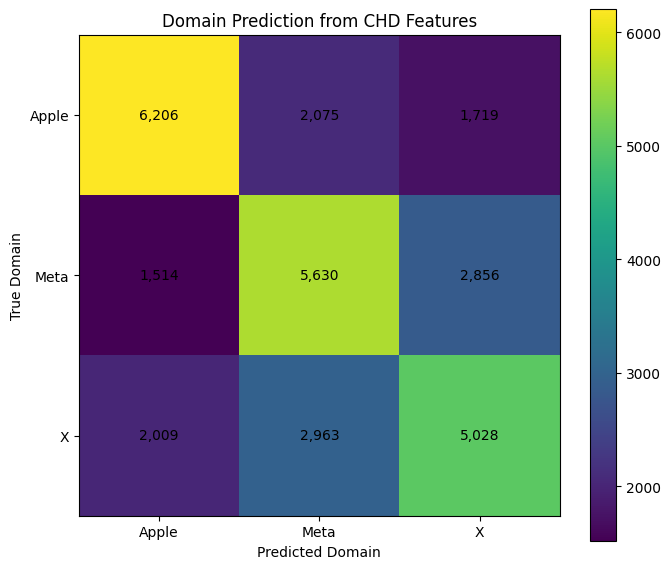


DOMAIN FEATURE IMPORTANCE
              feature  importance
   entity_consistency      0.1835
       context_length      0.1344
  semantic_similarity      0.1160
         claim_length      0.0944
  claim_context_ratio      0.0870
           entailment      0.0846
      lexical_overlap      0.0718
        contradiction      0.0646
     context_coverage      0.0643
              neutral      0.0567
lexical_contradiction      0.0288
   number_consistency      0.0139


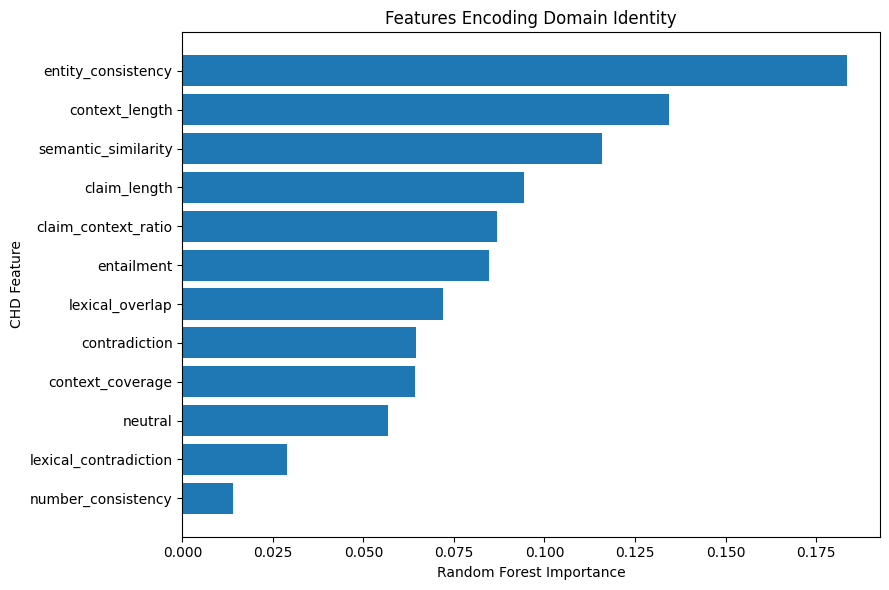


EFFECT-SIZE COUNTS
domain_a domain_b effect_size  count
   Apple     Meta       Large     10
   Apple     Meta      Medium      7
   Apple     Meta  Negligible     13
   Apple     Meta       Small     18
   Apple        X       Large      8
   Apple        X      Medium      6
   Apple        X  Negligible     13
   Apple        X       Small     21
       X     Meta      Medium      5
       X     Meta  Negligible     25
       X     Meta       Small     18

LARGE APPLE-SPECIFIC SHIFTS |d| >= 0.8
       label domain_a domain_b               feature  mean_a  mean_b  cohens_d
CONTRADICTED    Apple     Meta          claim_length 18.9592 13.8960    1.5495
CONTRADICTED    Apple     Meta   semantic_similarity  0.8203  0.6816    1.5390
CONTRADICTED    Apple        X          claim_length 18.9592 14.3860    1.4090
CONTRADICTED    Apple        X   semantic_similarity  0.8203  0.7230    1.3096
HALLUCINATED    Apple     Meta          claim_length 15.7792 13.5392    1.1610
HALLUCINATED    Apple 

In [24]:
# ============================================================
# CROSS-DOMAIN FEATURE DISTRIBUTION & DATASET ARTIFACT AUDIT
# ============================================================
#
# Purpose:
#   Investigate WHY cross-domain transfer is asymmetric:
#
#       Apple + X    -> Meta   : strong
#       Apple + Meta -> X      : strong
#       X + Meta     -> Apple  : weak
#
# This analysis checks whether:
#
#   1. Apple has substantially different CHD feature distributions.
#   2. The differences persist WITHIN the same class label.
#   3. Domain identity can be predicted from the 12 CHD features.
#   4. Certain features contain strong domain-specific signatures.
#
# IMPORTANT:
# Run the main CHD pipeline and the cross-domain cell first.
#
# Required objects:
#   apple_df, x_df, meta_df
#   X_apple, X_x, X_meta
#   FEATURE_NAMES
#
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from scipy.stats import (
    ks_2samp,
    wasserstein_distance
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

AUDIT_DIR = Path(
    "contextual_hallucination_detector_final/"
    "cross_domain_experiments/"
    "domain_shift_audit"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


LABEL_ORDER = [
    "CONTRADICTED",
    "HALLUCINATED",
    "SUPPORTED",
    "UNSUPPORTED"
]


print("=" * 100)
print("CROSS-DOMAIN FEATURE DISTRIBUTION & DATASET ARTIFACT AUDIT")
print("=" * 100)


# ============================================================
# 2. VERIFY REQUIRED OBJECTS
# ============================================================

required_objects = [
    "apple_df",
    "x_df",
    "meta_df",
    "X_apple",
    "X_x",
    "X_meta",
    "FEATURE_NAMES"
]


missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Run the previous CHD and cross-domain cells first.\n"
        f"Missing objects: {missing_objects}"
    )


# ============================================================
# 3. BASIC VALIDATION
# ============================================================

datasets = {
    "Apple": (apple_df, X_apple),
    "X": (x_df, X_x),
    "Meta": (meta_df, X_meta)
}


for domain_name, (domain_df, X_domain) in datasets.items():

    if len(domain_df) != len(X_domain):

        raise ValueError(
            f"{domain_name}: dataset/features row mismatch: "
            f"{len(domain_df)} vs {len(X_domain)}"
        )

    if X_domain.shape[1] != len(FEATURE_NAMES):

        raise ValueError(
            f"{domain_name}: expected {len(FEATURE_NAMES)} features, "
            f"found {X_domain.shape[1]}"
        )


print("\nDataset sizes:")

for domain_name, (domain_df, _) in datasets.items():

    print(
        f"{domain_name:6s}: {len(domain_df):,}"
    )


print(
    f"\nNumber of features: {len(FEATURE_NAMES)}"
)


# ============================================================
# 4. CREATE FEATURE DATAFRAMES
# ============================================================

def build_feature_dataframe(
    original_df,
    X_features,
    domain_name
):

    feature_df = pd.DataFrame(
        X_features,
        columns=FEATURE_NAMES
    )

    feature_df["label"] = (
        original_df["label"]
        .astype(str)
        .str.upper()
        .values
    )

    feature_df["domain"] = domain_name

    return feature_df


apple_features_df = build_feature_dataframe(
    apple_df,
    X_apple,
    "Apple"
)

x_features_df = build_feature_dataframe(
    x_df,
    X_x,
    "X"
)

meta_features_df = build_feature_dataframe(
    meta_df,
    X_meta,
    "Meta"
)


all_features_df = pd.concat(
    [
        apple_features_df,
        x_features_df,
        meta_features_df
    ],
    ignore_index=True
)


print("\nCombined feature dataset:")

print(
    all_features_df.shape
)


# ============================================================
# 5. GLOBAL FEATURE STATISTICS BY DOMAIN
# ============================================================

print("\n" + "=" * 100)
print("GLOBAL FEATURE MEANS BY DOMAIN")
print("=" * 100)


global_means = (
    all_features_df
    .groupby("domain")[FEATURE_NAMES]
    .mean()
    .T
)


print(
    global_means.round(4)
)


global_means.to_csv(
    AUDIT_DIR /
    "global_feature_means_by_domain.csv"
)


# ------------------------------------------------------------
# Standard deviation
# ------------------------------------------------------------

global_std = (
    all_features_df
    .groupby("domain")[FEATURE_NAMES]
    .std()
    .T
)


global_std.to_csv(
    AUDIT_DIR /
    "global_feature_std_by_domain.csv"
)


# ============================================================
# 6. FEATURE STATISTICS BY DOMAIN AND LABEL
# ============================================================

print("\n" + "=" * 100)
print("FEATURE MEANS BY DOMAIN AND LABEL")
print("=" * 100)


domain_label_means = (
    all_features_df
    .groupby(
        ["domain", "label"]
    )[FEATURE_NAMES]
    .mean()
)


print(
    domain_label_means.round(4)
)


domain_label_means.to_csv(
    AUDIT_DIR /
    "feature_means_by_domain_and_label.csv"
)


# ============================================================
# 7. SPECIAL INSPECTION: SUPPORTED
# ============================================================

print("\n" + "=" * 100)
print("SUPPORTED — FEATURE DISTRIBUTIONS")
print("=" * 100)


supported_df = all_features_df[
    all_features_df["label"] == "SUPPORTED"
]


supported_means = (
    supported_df
    .groupby("domain")[FEATURE_NAMES]
    .mean()
    .T
)


print(
    supported_means.round(4)
)


supported_means.to_csv(
    AUDIT_DIR /
    "supported_feature_means.csv"
)


# ============================================================
# 8. SPECIAL INSPECTION: HALLUCINATED
# ============================================================

print("\n" + "=" * 100)
print("HALLUCINATED — FEATURE DISTRIBUTIONS")
print("=" * 100)


hallucinated_df = all_features_df[
    all_features_df["label"] == "HALLUCINATED"
]


hallucinated_means = (
    hallucinated_df
    .groupby("domain")[FEATURE_NAMES]
    .mean()
    .T
)


print(
    hallucinated_means.round(4)
)


hallucinated_means.to_csv(
    AUDIT_DIR /
    "hallucinated_feature_means.csv"
)


# ============================================================
# 9. EFFECT SIZE FUNCTION
# ============================================================
#
# Cohen's d:
#
# |d| < 0.2   negligible
# 0.2-0.5     small
# 0.5-0.8     medium
# > 0.8       large
#
# ============================================================

def cohens_d(x1, x2):

    x1 = np.asarray(
        x1,
        dtype=float
    )

    x2 = np.asarray(
        x2,
        dtype=float
    )

    n1 = len(x1)
    n2 = len(x2)

    var1 = np.var(
        x1,
        ddof=1
    )

    var2 = np.var(
        x2,
        ddof=1
    )

    pooled_variance = (
        ((n1 - 1) * var1)
        +
        ((n2 - 1) * var2)
    ) / (
        n1 + n2 - 2
    )

    if pooled_variance <= 0:

        return 0.0

    pooled_std = np.sqrt(
        pooled_variance
    )

    return (
        np.mean(x1)
        -
        np.mean(x2)
    ) / pooled_std


# ============================================================
# 10. GLOBAL PAIRWISE DOMAIN SHIFT
# ============================================================

domain_pairs = [
    ("Apple", "X"),
    ("Apple", "Meta"),
    ("X", "Meta")
]


global_shift_rows = []


for domain_a, domain_b in domain_pairs:

    df_a = all_features_df[
        all_features_df["domain"] == domain_a
    ]

    df_b = all_features_df[
        all_features_df["domain"] == domain_b
    ]


    for feature in FEATURE_NAMES:

        a = df_a[
            feature
        ].values

        b = df_b[
            feature
        ].values


        d = cohens_d(
            a,
            b
        )


        ks_stat, ks_p = ks_2samp(
            a,
            b
        )


        wasserstein = wasserstein_distance(
            a,
            b
        )


        global_shift_rows.append({

            "domain_a":
                domain_a,

            "domain_b":
                domain_b,

            "feature":
                feature,

            "mean_a":
                float(np.mean(a)),

            "mean_b":
                float(np.mean(b)),

            "mean_difference":
                float(
                    np.mean(a)
                    -
                    np.mean(b)
                ),

            "cohens_d":
                float(d),

            "abs_cohens_d":
                float(abs(d)),

            "ks_statistic":
                float(ks_stat),

            "ks_pvalue":
                float(ks_p),

            "wasserstein_distance":
                float(wasserstein)

        })


global_shift_df = pd.DataFrame(
    global_shift_rows
)


global_shift_df = global_shift_df.sort_values(
    "abs_cohens_d",
    ascending=False
)


print("\n" + "=" * 100)
print("STRONGEST GLOBAL DOMAIN SHIFTS")
print("=" * 100)


print(
    global_shift_df[
        [
            "domain_a",
            "domain_b",
            "feature",
            "mean_a",
            "mean_b",
            "cohens_d",
            "ks_statistic",
            "wasserstein_distance"
        ]
    ]
    .head(25)
    .round(4)
    .to_string(
        index=False
    )
)


global_shift_df.to_csv(
    AUDIT_DIR /
    "global_pairwise_domain_shift.csv",
    index=False
)


# ============================================================
# 11. WITHIN-LABEL DOMAIN SHIFT
# ============================================================
#
# This is MORE IMPORTANT than the global comparison.
#
# Example:
#
# Compare Apple SUPPORTED vs X SUPPORTED
# instead of comparing all Apple vs all X.
#
# ============================================================

within_label_rows = []


for label in LABEL_ORDER:

    label_df = all_features_df[
        all_features_df["label"] == label
    ]


    for domain_a, domain_b in domain_pairs:

        df_a = label_df[
            label_df["domain"] == domain_a
        ]

        df_b = label_df[
            label_df["domain"] == domain_b
        ]


        for feature in FEATURE_NAMES:

            a = df_a[
                feature
            ].values

            b = df_b[
                feature
            ].values


            d = cohens_d(
                a,
                b
            )


            ks_stat, ks_p = ks_2samp(
                a,
                b
            )


            wasserstein = wasserstein_distance(
                a,
                b
            )


            within_label_rows.append({

                "label":
                    label,

                "domain_a":
                    domain_a,

                "domain_b":
                    domain_b,

                "feature":
                    feature,

                "mean_a":
                    float(
                        np.mean(a)
                    ),

                "mean_b":
                    float(
                        np.mean(b)
                    ),

                "mean_difference":
                    float(
                        np.mean(a)
                        -
                        np.mean(b)
                    ),

                "cohens_d":
                    float(d),

                "abs_cohens_d":
                    float(abs(d)),

                "ks_statistic":
                    float(ks_stat),

                "ks_pvalue":
                    float(ks_p),

                "wasserstein_distance":
                    float(wasserstein)

            })


within_label_shift_df = pd.DataFrame(
    within_label_rows
)


within_label_shift_df = (
    within_label_shift_df
    .sort_values(
        "abs_cohens_d",
        ascending=False
    )
)


within_label_shift_df.to_csv(
    AUDIT_DIR /
    "within_label_domain_shift.csv",
    index=False
)


print("\n" + "=" * 100)
print("TOP WITHIN-LABEL DOMAIN SHIFTS")
print("=" * 100)


print(
    within_label_shift_df[
        [
            "label",
            "domain_a",
            "domain_b",
            "feature",
            "mean_a",
            "mean_b",
            "cohens_d",
            "ks_statistic"
        ]
    ]
    .head(40)
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# 12. APPLE VS OTHER DOMAINS ONLY
# ============================================================
#
# Since Apple is the problematic held-out domain,
# isolate Apple-related shifts.
#
# ============================================================

apple_shift = within_label_shift_df[
    (
        within_label_shift_df[
            "domain_a"
        ] == "Apple"
    )
    |
    (
        within_label_shift_df[
            "domain_b"
        ] == "Apple"
    )
].copy()


apple_shift = apple_shift.sort_values(
    "abs_cohens_d",
    ascending=False
)


print("\n" + "=" * 100)
print("STRONGEST APPLE-SPECIFIC WITHIN-LABEL SHIFTS")
print("=" * 100)


print(
    apple_shift[
        [
            "label",
            "domain_a",
            "domain_b",
            "feature",
            "mean_a",
            "mean_b",
            "cohens_d",
            "ks_statistic"
        ]
    ]
    .head(30)
    .round(4)
    .to_string(
        index=False
    )
)


apple_shift.to_csv(
    AUDIT_DIR /
    "apple_specific_domain_shift.csv",
    index=False
)


# ============================================================
# 13. DOMAIN CLASSIFICATION DATASET
# ============================================================
#
# Question:
#
# Can a classifier predict:
#       Apple / X / Meta
#
# using ONLY the 12 CHD features?
#
# If yes, feature space contains domain-specific signatures.
#
# ============================================================

print("\n" + "=" * 100)
print("DOMAIN PREDICTABILITY TEST")
print("=" * 100)


X_domain = (
    all_features_df[
        FEATURE_NAMES
    ]
    .values
    .astype(
        np.float32
    )
)


domain_encoder = LabelEncoder()


y_domain = domain_encoder.fit_transform(
    all_features_df[
        "domain"
    ]
)


print(
    "\nDomain mapping:"
)


for i, domain in enumerate(
    domain_encoder.classes_
):

    print(
        f"{i} -> {domain}"
    )


# ============================================================
# 14. LOGISTIC REGRESSION DOMAIN CLASSIFIER
# ============================================================

domain_logreg = Pipeline(
    [
        (
            "scaler",
            StandardScaler()
        ),

        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=SEED
            )
        )
    ]
)


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


print(
    "\nRunning 5-fold cross-validated "
    "domain prediction..."
)


domain_predictions = cross_val_predict(
    domain_logreg,
    X_domain,
    y_domain,
    cv=cv,
    n_jobs=-1
)


domain_accuracy = accuracy_score(
    y_domain,
    domain_predictions
)


domain_balanced_accuracy = (
    balanced_accuracy_score(
        y_domain,
        domain_predictions
    )
)


domain_macro_f1 = f1_score(
    y_domain,
    domain_predictions,
    average="macro"
)


print("\nDOMAIN CLASSIFICATION RESULTS")

print("-" * 60)

print(
    f"Accuracy          : "
    f"{domain_accuracy:.4f}"
)

print(
    f"Balanced Accuracy : "
    f"{domain_balanced_accuracy:.4f}"
)

print(
    f"Macro F1          : "
    f"{domain_macro_f1:.4f}"
)


print("\nClassification Report:\n")


print(
    classification_report(
        y_domain,
        domain_predictions,
        target_names=
            domain_encoder.classes_,
        digits=4
    )
)


# ============================================================
# 15. DOMAIN CONFUSION MATRIX
# ============================================================

domain_cm = confusion_matrix(
    y_domain,
    domain_predictions
)


domain_cm_df = pd.DataFrame(
    domain_cm,
    index=domain_encoder.classes_,
    columns=domain_encoder.classes_
)


print(
    "\nDomain Confusion Matrix:\n"
)

print(
    domain_cm_df
)


domain_cm_df.to_csv(
    AUDIT_DIR /
    "domain_classifier_confusion_matrix.csv"
)


# ============================================================
# 16. DOMAIN CLASSIFIER CONFUSION MATRIX PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 6)
)


im = ax.imshow(
    domain_cm
)


ax.set_xticks(
    np.arange(
        len(
            domain_encoder.classes_
        )
    )
)


ax.set_yticks(
    np.arange(
        len(
            domain_encoder.classes_
        )
    )
)


ax.set_xticklabels(
    domain_encoder.classes_
)


ax.set_yticklabels(
    domain_encoder.classes_
)


ax.set_xlabel(
    "Predicted Domain"
)


ax.set_ylabel(
    "True Domain"
)


ax.set_title(
    "Domain Prediction from CHD Features"
)


for i in range(
    domain_cm.shape[0]
):

    for j in range(
        domain_cm.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{domain_cm[i, j]:,}",
            ha="center",
            va="center"
        )


fig.colorbar(
    im,
    ax=ax
)


plt.tight_layout()


plt.savefig(
    AUDIT_DIR /
    "domain_classifier_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 17. RANDOM FOREST DOMAIN CLASSIFIER
# ============================================================
#
# Used mainly to estimate which features encode
# domain identity.
#
# ============================================================

print("\n" + "=" * 100)
print("DOMAIN FEATURE IMPORTANCE")
print("=" * 100)


domain_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1,
    class_weight="balanced"
)


domain_rf.fit(
    X_domain,
    y_domain
)


domain_importance = pd.DataFrame(
    {
        "feature":
            FEATURE_NAMES,

        "importance":
            domain_rf.feature_importances_
    }
)


domain_importance = (
    domain_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    domain_importance
    .round(4)
    .to_string(
        index=False
    )
)


domain_importance.to_csv(
    AUDIT_DIR /
    "domain_feature_importance.csv",
    index=False
)


# ============================================================
# 18. FEATURE IMPORTANCE PLOT
# ============================================================

plot_df = (
    domain_importance
    .sort_values(
        "importance",
        ascending=True
    )
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.barh(
    plot_df["feature"],
    plot_df["importance"]
)


ax.set_xlabel(
    "Random Forest Importance"
)


ax.set_ylabel(
    "CHD Feature"
)


ax.set_title(
    "Features Encoding Domain Identity"
)


plt.tight_layout()


plt.savefig(
    AUDIT_DIR /
    "domain_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 19. PLOT FEATURE MEANS BY DOMAIN
# ============================================================

for feature in FEATURE_NAMES:

    means = (
        all_features_df
        .groupby("domain")[
            feature
        ]
        .mean()
        .reindex(
            [
                "Apple",
                "X",
                "Meta"
            ]
        )
    )


    fig, ax = plt.subplots(
        figsize=(7, 5)
    )


    ax.bar(
        means.index,
        means.values
    )


    ax.set_ylabel(
        f"Mean {feature}"
    )


    ax.set_xlabel(
        "Domain"
    )


    ax.set_title(
        f"{feature}: Mean by Domain"
    )


    plt.tight_layout()


    plt.savefig(
        AUDIT_DIR /
        f"mean_{feature}_by_domain.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.close()


# ============================================================
# 20. LABEL-SPECIFIC FEATURE PLOTS
# ============================================================
#
# Particularly useful for SUPPORTED/HALLUCINATED.
#
# ============================================================

critical_labels = [
    "SUPPORTED",
    "HALLUCINATED"
]


critical_features = [
    "semantic_similarity",
    "lexical_overlap",
    "context_coverage",
    "entailment",
    "contradiction",
    "neutral"
]


for label in critical_labels:

    label_subset = all_features_df[
        all_features_df[
            "label"
        ] == label
    ]


    for feature in critical_features:

        if feature not in FEATURE_NAMES:

            continue


        means = (
            label_subset
            .groupby("domain")[
                feature
            ]
            .mean()
            .reindex(
                [
                    "Apple",
                    "X",
                    "Meta"
                ]
            )
        )


        fig, ax = plt.subplots(
            figsize=(7, 5)
        )


        ax.bar(
            means.index,
            means.values
        )


        ax.set_ylabel(
            f"Mean {feature}"
        )


        ax.set_xlabel(
            "Domain"
        )


        ax.set_title(
            f"{label}: {feature}"
        )


        plt.tight_layout()


        plt.savefig(
            AUDIT_DIR /
            f"{label.lower()}_{feature}_by_domain.png",
            dpi=300,
            bbox_inches="tight"
        )


        plt.close()


# ============================================================
# 21. LARGE EFFECT COUNTS
# ============================================================

def effect_category(
    abs_d
):

    if abs_d < 0.2:

        return "Negligible"

    elif abs_d < 0.5:

        return "Small"

    elif abs_d < 0.8:

        return "Medium"

    else:

        return "Large"


within_label_shift_df[
    "effect_size"
] = (
    within_label_shift_df[
        "abs_cohens_d"
    ]
    .apply(
        effect_category
    )
)


effect_counts = (
    within_label_shift_df
    .groupby(
        [
            "domain_a",
            "domain_b",
            "effect_size"
        ]
    )
    .size()
    .reset_index(
        name="count"
    )
)


print("\n" + "=" * 100)
print("EFFECT-SIZE COUNTS")
print("=" * 100)


print(
    effect_counts
    .to_string(
        index=False
    )
)


effect_counts.to_csv(
    AUDIT_DIR /
    "effect_size_counts.csv",
    index=False
)


# ============================================================
# 22. APPLE VS X/META SUMMARY
# ============================================================

apple_large_shifts = apple_shift[
    apple_shift[
        "abs_cohens_d"
    ] >= 0.8
].copy()


print("\n" + "=" * 100)
print("LARGE APPLE-SPECIFIC SHIFTS |d| >= 0.8")
print("=" * 100)


if len(
    apple_large_shifts
) == 0:

    print(
        "No Apple-specific large effects detected."
    )

else:

    print(
        apple_large_shifts[
            [
                "label",
                "domain_a",
                "domain_b",
                "feature",
                "mean_a",
                "mean_b",
                "cohens_d"
            ]
        ]
        .round(4)
        .to_string(
            index=False
        )
    )


apple_large_shifts.to_csv(
    AUDIT_DIR /
    "large_apple_specific_shifts.csv",
    index=False
)


# ============================================================
# 23. SAVE DOMAIN CLASSIFIER SUMMARY
# ============================================================

audit_summary = {

    "n_domains":
        3,

    "n_total_samples":
        int(
            len(
                all_features_df
            )
        ),

    "samples_per_domain": {

        "Apple":
            int(
                len(
                    apple_features_df
                )
            ),

        "X":
            int(
                len(
                    x_features_df
                )
            ),

        "Meta":
            int(
                len(
                    meta_features_df
                )
            )
    },

    "n_features":
        int(
            len(
                FEATURE_NAMES
            )
        ),

    "domain_classifier": {

        "accuracy":
            float(
                domain_accuracy
            ),

        "balanced_accuracy":
            float(
                domain_balanced_accuracy
            ),

        "macro_f1":
            float(
                domain_macro_f1
            )
    },

    "largest_domain_features":
        domain_importance
        .head(5)
        .to_dict(
            orient="records"
        ),

    "n_large_apple_specific_shifts":
        int(
            len(
                apple_large_shifts
            )
        )
}


with open(
    AUDIT_DIR /
    "domain_shift_audit_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        audit_summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 24. FINAL DIAGNOSTIC SUMMARY
# ============================================================

print("\n\n" + "=" * 100)
print("DOMAIN SHIFT AUDIT — FINAL SUMMARY")
print("=" * 100)


print(
    f"\nDomain classifier accuracy : "
    f"{domain_accuracy:.4f}"
)


print(
    f"Domain classifier Macro-F1 : "
    f"{domain_macro_f1:.4f}"
)


print(
    f"\nLarge Apple-specific within-label shifts "
    f"(|d| >= 0.8): "
    f"{len(apple_large_shifts)}"
)


print(
    "\nTop 5 features encoding domain identity:"
)


for rank, row in (
    domain_importance
    .head(5)
    .iterrows()
):

    print(
        f"  {rank + 1}. "
        f"{row['feature']}: "
        f"{row['importance']:.4f}"
    )


print(
    "\nTop 10 Apple-specific within-label shifts:"
)


print(
    apple_shift[
        [
            "label",
            "domain_a",
            "domain_b",
            "feature",
            "cohens_d",
            "ks_statistic"
        ]
    ]
    .head(10)
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# 25. AUTOMATIC INTERPRETATION
# ============================================================

print("\n" + "=" * 100)
print("AUTOMATIC INTERPRETATION")
print("=" * 100)


if domain_accuracy >= 0.90:

    print(
        "\n[STRONG DOMAIN SIGNATURE]"
    )

    print(
        "The CHD feature space allows very accurate "
        "prediction of dataset/domain identity."
    )

    print(
        "This indicates substantial domain-specific "
        "feature structure."
    )


elif domain_accuracy >= 0.70:

    print(
        "\n[MODERATE DOMAIN SIGNATURE]"
    )

    print(
        "The CHD features contain meaningful "
        "domain-specific information."
    )


else:

    print(
        "\n[WEAK DOMAIN SIGNATURE]"
    )

    print(
        "Domain identity is not strongly recoverable "
        "from the CHD features alone."
    )


if len(
    apple_large_shifts
) >= 5:

    print(
        "\n[APPLE DISTRIBUTION SHIFT DETECTED]"
    )

    print(
        "Multiple large within-label feature shifts "
        "were detected between Apple and the other domains."
    )

    print(
        "This provides a plausible explanation for the "
        "asymmetric X + Meta -> Apple transfer failure."
    )


elif len(
    apple_large_shifts
) > 0:

    print(
        "\n[SOME APPLE-SPECIFIC SHIFT]"
    )

    print(
        "A limited number of large Apple-specific "
        "feature differences were detected."
    )


else:

    print(
        "\n[NO LARGE APPLE-SPECIFIC SHIFT]"
    )

    print(
        "The transfer failure cannot be explained by "
        "large univariate feature shifts alone."
    )


print(
    "\nAudit outputs saved to:"
)

print(
    AUDIT_DIR
)


print("\n" + "=" * 100)
print("AUDIT COMPLETE")
print("=" * 100)

## 54. Controlled Contextual Degradation Stress Test

This section adds a **fully automatic, controlled degradation experiment** at 0%, 20%, 40%, 60%, and 80% corruption.

It uses three perturbation families:

1. **Irrelevant-context injection** — preserves the original evidence and adds distractor text; therefore Accuracy and Macro-F1 remain directly interpretable against the original labels.
2. **Claim-relevant evidence removal** — progressively removes context most relevant to the claim. Because this intervention can genuinely change the semantic relation between the claim and context, results are reported primarily as **original-label retention**, prediction-flip rate, confidence, and CHS sensitivity rather than being over-interpreted as ordinary classification accuracy.
3. **Context truncation** — progressively shortens the context. As with evidence removal, the original relation can change, so this is treated as a sensitivity/stress test.

The experiment is deterministic, stratified by class, uses the already trained calibrated CHD model, and writes paper-ready CSV tables and figures under `contextual_hallucination_detector_final/controlled_degradation/`.


In [25]:
# ============================================================
# 54. CONTROLLED CONTEXTUAL DEGRADATION STRESS TEST
#     Publication-oriented extension: no human annotation
# ============================================================

from pathlib import Path
import hashlib
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from scipy.stats import spearmanr

print("\n" + "=" * 78)
print("54. CONTROLLED CONTEXTUAL DEGRADATION STRESS TEST")
print("=" * 78)

# ------------------------------------------------------------
# 54.1 Preconditions
# ------------------------------------------------------------
_required = [
    "test_df", "compute_features", "calculate_chs", "calibrated_model",
    "label_encoder", "FEATURE_NAMES", "SEED"
]
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run the main CHD pipeline first. Missing objects: " + ", ".join(_missing)
    )

DEG_OUTPUT_DIR = Path(OUTPUT_DIR) / "controlled_degradation"
DEG_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEGRADATION_LEVELS = [0.00, 0.20, 0.40, 0.60, 0.80]
DEGRADATION_MODES = [
    "irrelevant_injection",
    "evidence_removal",
    "context_truncation",
]

# 300 gives 4,500 perturbed examples (300 x 5 levels x 3 modes).
# Increase only if runtime is acceptable on the available GPU.
DEGRADATION_SAMPLE_SIZE = min(300, len(test_df))

# ------------------------------------------------------------
# 54.2 Deterministic, class-stratified evaluation sample
# ------------------------------------------------------------
def _stratified_sample(frame, n_total, seed=42):
    frame = frame.copy()
    classes = sorted(frame["label"].astype(str).unique())
    base = n_total // len(classes)
    remainder = n_total % len(classes)

    parts = []
    for i, lab in enumerate(classes):
        group = frame[frame["label"].astype(str) == lab]
        n_take = min(len(group), base + (1 if i < remainder else 0))
        parts.append(group.sample(n=n_take, random_state=seed + i))

    sampled = pd.concat(parts, ignore_index=False)

    # If a small class prevented reaching n_total, fill deterministically.
    if len(sampled) < n_total:
        remaining = frame.drop(index=sampled.index, errors="ignore")
        n_more = min(n_total - len(sampled), len(remaining))
        if n_more > 0:
            sampled = pd.concat([
                sampled,
                remaining.sample(n=n_more, random_state=seed + 999)
            ])

    return sampled.sample(frac=1.0, random_state=seed).reset_index(drop=True)


deg_sample = _stratified_sample(test_df, DEGRADATION_SAMPLE_SIZE, SEED)
print("\nControlled-degradation sample:", len(deg_sample))
print(deg_sample["label"].value_counts().sort_index())

# Stable row key used to select distractors reproducibly.
def _stable_key(row, fallback_index):
    if "id" in row and pd.notna(row["id"]):
        return str(row["id"])
    raw = f"{fallback_index}|{row.get('claim','')}|{row.get('context','')}"
    return hashlib.md5(raw.encode("utf-8")).hexdigest()

# ------------------------------------------------------------
# 54.3 Text helpers
# ------------------------------------------------------------
def _split_sentences_cd(text):
    text = str(text).strip()
    if not text:
        return []
    sents = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sents if s.strip()]


def _tokens_cd(text):
    return re.findall(r"\S+", str(text))


def _truncate_context(context, level):
    """Keep 100%, 80%, 60%, 40%, or 20% of the original words."""
    words = _tokens_cd(context)
    if not words or level <= 0:
        return str(context)
    keep = max(1, int(round(len(words) * (1.0 - level))))
    return " ".join(words[:keep])


def _single_sentence_evidence_removal(context, claim, level):
    """
    Fallback for one-sentence contexts.
    Remove claim-overlapping content first, then deterministic remaining tokens,
    until approximately `level` of the context has been removed.
    """
    words = _tokens_cd(context)
    if not words or level <= 0:
        return str(context)

    remove_n = min(len(words) - 1, int(round(len(words) * level)))
    if remove_n <= 0:
        return str(context)

    claim_terms = set(re.findall(r"\b\w+\b", str(claim).lower()))
    normalized = [re.sub(r"\W+", "", w.lower()) for w in words]

    overlap_idx = [i for i, w in enumerate(normalized) if w and w in claim_terms]
    other_idx = [i for i in range(len(words)) if i not in set(overlap_idx)]
    remove_idx = set((overlap_idx + other_idx)[:remove_n])
    kept = [w for i, w in enumerate(words) if i not in remove_idx]
    return " ".join(kept) if kept else words[-1]


def _prepare_relevance_rankings(sample):
    """
    Rank each multi-sentence context once by semantic relevance to its claim.
    This avoids re-encoding the same context separately for every level.
    """
    rankings = {}
    print("\nRanking context sentences by claim relevance...")
    for i, row in sample.iterrows():
        sents = _split_sentences_cd(row["context"])
        if len(sents) <= 1:
            rankings[i] = sents
            continue

        c_emb = sentence_model.encode(
            [str(row["claim"])], convert_to_numpy=True, normalize_embeddings=True
        )[0]
        s_emb = sentence_model.encode(
            sents, convert_to_numpy=True, normalize_embeddings=True
        )
        sims = s_emb @ c_emb
        order = np.argsort(-sims)
        rankings[i] = [sents[j] for j in order]

        if (i + 1) % 50 == 0:
            print(f"  ranked {i + 1}/{len(sample)}")
    return rankings


_relevance_rankings = _prepare_relevance_rankings(deg_sample)


def _remove_relevant_evidence(context, claim, level, ranked_sentences):
    """
    Remove the most claim-relevant sentences until roughly `level` of the
    original word mass is removed. A one-sentence fallback removes words.
    """
    if level <= 0:
        return str(context)

    sents_original = _split_sentences_cd(context)
    if len(sents_original) <= 1:
        return _single_sentence_evidence_removal(context, claim, level)

    total_words = max(1, len(_tokens_cd(context)))
    target_remove = max(1, int(round(total_words * level)))

    removed_words = 0
    remove_set = set()
    for sent in ranked_sentences:
        # Always leave at least one sentence so feature extraction remains valid.
        if len(remove_set) >= len(sents_original) - 1:
            break
        remove_set.add(sent)
        removed_words += len(_tokens_cd(sent))
        if removed_words >= target_remove:
            break

    kept = [s for s in sents_original if s not in remove_set]
    if not kept:
        kept = [sents_original[-1]]
    return " ".join(kept)


# Build a distractor bank once. We retain each original context and ADD noise,
# which makes this the label-preserving perturbation family in this experiment.
_distractor_bank = []
for i, row in deg_sample.iterrows():
    sents = _split_sentences_cd(row["context"])
    if not sents:
        sents = [str(row["context"])]
    for s in sents:
        _distractor_bank.append({
            "row_idx": i,
            "topic": str(row.get("topic", "")),
            "text": s,
        })


def _inject_irrelevant_context(context, row_idx, topic, level, stable_key):
    """
    Append distractor text from other examples, preferring a different topic.
    The amount added is approximately `level * original_word_count`.
    Original evidence is never removed.
    """
    if level <= 0:
        return str(context)

    orig_words = max(1, len(_tokens_cd(context)))
    target_add = max(1, int(round(orig_words * level)))

    candidates = [
        x for x in _distractor_bank
        if x["row_idx"] != row_idx and x["topic"] != str(topic)
    ]
    if not candidates:
        candidates = [x for x in _distractor_bank if x["row_idx"] != row_idx]
    if not candidates:
        return str(context)

    # Stable local RNG: same sample + same level always produces same corruption.
    seed_material = f"{SEED}|{stable_key}|{level:.2f}|irrelevant_injection"
    local_seed = int(hashlib.md5(seed_material.encode("utf-8")).hexdigest()[:8], 16)
    rng = np.random.default_rng(local_seed)
    order = rng.permutation(len(candidates))

    selected = []
    added = 0
    for j in order:
        text = candidates[int(j)]["text"]
        selected.append(text)
        added += len(_tokens_cd(text))
        if added >= target_add:
            break

    # Crop the last injected segment if the bank sentence is much longer than needed.
    injected_words = _tokens_cd(" ".join(selected))[:target_add]
    distractor = " ".join(injected_words)
    return (str(context).strip() + " " + distractor).strip()


# ------------------------------------------------------------
# 54.4 Construct all perturbations
# ------------------------------------------------------------
records = []
contexts_by_mode = {m: [] for m in DEGRADATION_MODES}
claims_by_mode = {m: [] for m in DEGRADATION_MODES}
meta_by_mode = {m: [] for m in DEGRADATION_MODES}

for i, row in deg_sample.iterrows():
    context = str(row["context"])
    claim = str(row["claim"])
    stable_key = _stable_key(row, i)

    for level in DEGRADATION_LEVELS:
        transformations = {
            "irrelevant_injection": _inject_irrelevant_context(
                context=context,
                row_idx=i,
                topic=row.get("topic", ""),
                level=level,
                stable_key=stable_key,
            ),
            "evidence_removal": _remove_relevant_evidence(
                context=context,
                claim=claim,
                level=level,
                ranked_sentences=_relevance_rankings[i],
            ),
            "context_truncation": _truncate_context(context, level),
        }

        for mode, degraded_context in transformations.items():
            contexts_by_mode[mode].append(degraded_context)
            claims_by_mode[mode].append(claim)
            meta_by_mode[mode].append({
                "sample_index": int(i),
                "id": row.get("id", stable_key),
                "topic": row.get("topic", ""),
                "true_label": str(row["label"]),
                "true_label_id": int(label_encoder.transform([str(row["label"])])[0]),
                "degradation_mode": mode,
                "degradation_level": float(level),
                "degradation_percent": int(round(level * 100)),
                "original_context_words": int(len(_tokens_cd(context))),
                "degraded_context_words": int(len(_tokens_cd(degraded_context))),
            })

print("\nPrepared perturbed examples:")
for mode in DEGRADATION_MODES:
    print(f"  {mode:24s}: {len(contexts_by_mode[mode])}")

# ------------------------------------------------------------
# 54.5 Feature extraction + calibrated CHD predictions
# ------------------------------------------------------------
all_prediction_frames = []

for mode in DEGRADATION_MODES:
    print("\n" + "-" * 78)
    print("Processing:", mode)
    print("-" * 78)

    X_deg = compute_features(
        contexts_by_mode[mode],
        claims_by_mode[mode],
        batch_size=64,
        nli_batch_size=32,
    )

    proba = calibrated_model.predict_proba(X_deg)
    pred_ids = np.argmax(proba, axis=1)
    confidence = np.max(proba, axis=1)
    chs = calculate_chs(X_deg)

    frame = pd.DataFrame(meta_by_mode[mode])
    frame["predicted_label_id"] = pred_ids.astype(int)
    frame["predicted_label"] = label_encoder.inverse_transform(pred_ids)
    frame["confidence"] = confidence.astype(float)
    frame["CHS"] = chs.astype(float)
    frame["correct_vs_original_label"] = (
        frame["predicted_label_id"].to_numpy() == frame["true_label_id"].to_numpy()
    ).astype(int)

    # Probability assigned to the original/reference class.
    true_ids = frame["true_label_id"].to_numpy(dtype=int)
    frame["original_label_probability"] = proba[np.arange(len(proba)), true_ids]

    # Compare every perturbed prediction with that same example's clean (0%) prediction.
    clean_pred_map = (
        frame[frame["degradation_percent"] == 0]
        .set_index("sample_index")["predicted_label_id"]
        .to_dict()
    )
    frame["clean_predicted_label_id"] = frame["sample_index"].map(clean_pred_map).astype(int)
    frame["prediction_flipped_from_clean"] = (
        frame["predicted_label_id"] != frame["clean_predicted_label_id"]
    ).astype(int)

    # Store probabilities for optional class-transition analysis.
    for class_id, class_name in enumerate(label_encoder.classes_):
        safe = re.sub(r"[^A-Za-z0-9]+", "_", str(class_name)).strip("_").lower()
        frame[f"prob_{safe}"] = proba[:, class_id]

    frame.to_csv(DEG_OUTPUT_DIR / f"{mode}_predictions.csv", index=False)
    all_prediction_frames.append(frame)

controlled_deg_predictions = pd.concat(all_prediction_frames, ignore_index=True)
controlled_deg_predictions.to_csv(
    DEG_OUTPUT_DIR / "controlled_degradation_all_predictions.csv", index=False
)

# ------------------------------------------------------------
# 54.6 Aggregate metrics
# ------------------------------------------------------------
summary_rows = []

for (mode, pct), g in controlled_deg_predictions.groupby(
    ["degradation_mode", "degradation_percent"], sort=True
):
    y_true = g["true_label_id"].to_numpy(dtype=int)
    y_pred = g["predicted_label_id"].to_numpy(dtype=int)

    macro_f1 = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )[2]

    correct_mask = g["correct_vs_original_label"].to_numpy(dtype=bool)
    incorrect_mask = ~correct_mask

    summary_rows.append({
        "degradation_mode": mode,
        "degradation_percent": int(pct),
        "n": int(len(g)),
        # For irrelevant_injection these are ordinary label-preserving performance metrics.
        # For removal/truncation interpret them as retention vs ORIGINAL labels.
        "accuracy_vs_original_label": float(accuracy_score(y_true, y_pred)),
        "macro_f1_vs_original_label": float(macro_f1),
        "mean_CHS": float(g["CHS"].mean()),
        "std_CHS": float(g["CHS"].std(ddof=1)),
        "mean_confidence": float(g["confidence"].mean()),
        "mean_original_label_probability": float(g["original_label_probability"].mean()),
        "prediction_flip_rate_from_clean": float(g["prediction_flipped_from_clean"].mean()),
        "mean_confidence_correct": float(g.loc[correct_mask, "confidence"].mean()) if correct_mask.any() else np.nan,
        "mean_confidence_incorrect": float(g.loc[incorrect_mask, "confidence"].mean()) if incorrect_mask.any() else np.nan,
        "mean_context_words": float(g["degraded_context_words"].mean()),
    })

controlled_deg_summary = pd.DataFrame(summary_rows).sort_values(
    ["degradation_mode", "degradation_percent"]
).reset_index(drop=True)
controlled_deg_summary.to_csv(
    DEG_OUTPUT_DIR / "controlled_degradation_summary.csv", index=False
)

print("\nControlled degradation summary:")
print(controlled_deg_summary.to_string(index=False))

# Per-class summary is useful for diagnosing HALLUCINATED vs UNSUPPORTED behavior.
per_class_rows = []
for (mode, pct, true_label), g in controlled_deg_predictions.groupby(
    ["degradation_mode", "degradation_percent", "true_label"], sort=True
):
    per_class_rows.append({
        "degradation_mode": mode,
        "degradation_percent": int(pct),
        "true_label": true_label,
        "n": int(len(g)),
        "original_label_recall": float(g["correct_vs_original_label"].mean()),
        "mean_CHS": float(g["CHS"].mean()),
        "mean_confidence": float(g["confidence"].mean()),
        "mean_original_label_probability": float(g["original_label_probability"].mean()),
        "prediction_flip_rate_from_clean": float(g["prediction_flipped_from_clean"].mean()),
    })

controlled_deg_per_class = pd.DataFrame(per_class_rows)
controlled_deg_per_class.to_csv(
    DEG_OUTPUT_DIR / "controlled_degradation_per_class.csv", index=False
)

# ------------------------------------------------------------
# 54.7 Trend / monotonicity diagnostics
# ------------------------------------------------------------
trend_rows = []
for mode, g in controlled_deg_summary.groupby("degradation_mode"):
    x = g["degradation_percent"].to_numpy(dtype=float)
    for metric in [
        "accuracy_vs_original_label",
        "macro_f1_vs_original_label",
        "mean_CHS",
        "mean_confidence",
        "mean_original_label_probability",
        "prediction_flip_rate_from_clean",
    ]:
        y = g[metric].to_numpy(dtype=float)
        rho, p = spearmanr(x, y)
        slope = np.polyfit(x, y, 1)[0] if len(np.unique(x)) > 1 else np.nan
        trend_rows.append({
            "degradation_mode": mode,
            "metric": metric,
            "spearman_rho_across_levels": float(rho),
            "spearman_p_value": float(p),
            "linear_slope_per_1_percent": float(slope),
        })

controlled_deg_trends = pd.DataFrame(trend_rows)
controlled_deg_trends.to_csv(
    DEG_OUTPUT_DIR / "controlled_degradation_trends.csv", index=False
)

print("\nTrend diagnostics:")
print(controlled_deg_trends.to_string(index=False))

# ------------------------------------------------------------
# 54.8 Prediction-transition matrices (0% -> 80%)
# ------------------------------------------------------------
transition_frames = []
for mode in DEGRADATION_MODES:
    clean = controlled_deg_predictions[
        (controlled_deg_predictions["degradation_mode"] == mode) &
        (controlled_deg_predictions["degradation_percent"] == 0)
    ][["sample_index", "predicted_label"]].rename(columns={"predicted_label": "prediction_0"})

    severe = controlled_deg_predictions[
        (controlled_deg_predictions["degradation_mode"] == mode) &
        (controlled_deg_predictions["degradation_percent"] == 80)
    ][["sample_index", "predicted_label"]].rename(columns={"predicted_label": "prediction_80"})

    trans = clean.merge(severe, on="sample_index", how="inner")
    matrix = pd.crosstab(trans["prediction_0"], trans["prediction_80"], dropna=False)
    matrix.to_csv(DEG_OUTPUT_DIR / f"transition_0_to_80_{mode}.csv")

# ------------------------------------------------------------
# 54.9 Publication-ready figures
# ------------------------------------------------------------
# Figure A: Macro-F1 / original-label retention
plt.figure(figsize=(9, 6))
for mode, g in controlled_deg_summary.groupby("degradation_mode"):
    plt.plot(
        g["degradation_percent"],
        g["macro_f1_vs_original_label"],
        marker="o",
        label=mode.replace("_", " ").title(),
    )
plt.xlabel("Context Degradation (%)")
plt.ylabel("Macro-F1 vs Original Labels")
plt.title("CHD Sensitivity to Controlled Context Degradation")
plt.legend()
plt.tight_layout()
plt.savefig(DEG_OUTPUT_DIR / "degradation_macro_f1.png", dpi=300)
plt.close()

# Figure B: CHS
plt.figure(figsize=(9, 6))
for mode, g in controlled_deg_summary.groupby("degradation_mode"):
    plt.plot(
        g["degradation_percent"], g["mean_CHS"], marker="o",
        label=mode.replace("_", " ").title(),
    )
plt.xlabel("Context Degradation (%)")
plt.ylabel("Mean CHS")
plt.title("Contextual Hallucination Score under Degradation")
plt.legend()
plt.tight_layout()
plt.savefig(DEG_OUTPUT_DIR / "degradation_chs.png", dpi=300)
plt.close()

# Figure C: confidence
plt.figure(figsize=(9, 6))
for mode, g in controlled_deg_summary.groupby("degradation_mode"):
    plt.plot(
        g["degradation_percent"], g["mean_confidence"], marker="o",
        label=mode.replace("_", " ").title(),
    )
plt.xlabel("Context Degradation (%)")
plt.ylabel("Mean Prediction Confidence")
plt.title("CHD Confidence under Context Degradation")
plt.legend()
plt.tight_layout()
plt.savefig(DEG_OUTPUT_DIR / "degradation_confidence.png", dpi=300)
plt.close()

# Figure D: prediction flip rate
plt.figure(figsize=(9, 6))
for mode, g in controlled_deg_summary.groupby("degradation_mode"):
    plt.plot(
        g["degradation_percent"],
        g["prediction_flip_rate_from_clean"],
        marker="o",
        label=mode.replace("_", " ").title(),
    )
plt.xlabel("Context Degradation (%)")
plt.ylabel("Prediction Flip Rate from Clean Context")
plt.title("Prediction Instability under Context Degradation")
plt.legend()
plt.tight_layout()
plt.savefig(DEG_OUTPUT_DIR / "degradation_flip_rate.png", dpi=300)
plt.close()

# ------------------------------------------------------------
# 54.10 Paper-ready compact table + machine-readable summary
# ------------------------------------------------------------
paper_table = controlled_deg_summary[[
    "degradation_mode",
    "degradation_percent",
    "accuracy_vs_original_label",
    "macro_f1_vs_original_label",
    "mean_CHS",
    "mean_confidence",
    "mean_original_label_probability",
    "prediction_flip_rate_from_clean",
]].copy()
paper_table.to_csv(DEG_OUTPUT_DIR / "paper_ready_degradation_table.csv", index=False)

# Label-preserving subset for claims about ordinary accuracy/F1 robustness.
label_preserving_table = paper_table[
    paper_table["degradation_mode"] == "irrelevant_injection"
].copy()
label_preserving_table.to_csv(
    DEG_OUTPUT_DIR / "paper_ready_label_preserving_injection.csv", index=False
)

summary_json = {
    "sample_size": int(len(deg_sample)),
    "degradation_levels_percent": [int(x * 100) for x in DEGRADATION_LEVELS],
    "modes": DEGRADATION_MODES,
    "interpretation_note": (
        "Irrelevant-context injection preserves original evidence, so accuracy and Macro-F1 "
        "against original labels are ordinary robustness metrics. Evidence removal and context "
        "truncation can alter the semantic claim-context relation; their accuracy/F1 columns "
        "should be described as original-label retention, while CHS, confidence, class-probability "
        "and prediction-transition trends are the primary sensitivity measures."
    ),
    "output_directory": str(DEG_OUTPUT_DIR),
}
with open(DEG_OUTPUT_DIR / "controlled_degradation_experiment.json", "w", encoding="utf-8") as f:
    json.dump(summary_json, f, indent=2)

print("\n" + "=" * 78)
print("CONTROLLED CONTEXTUAL DEGRADATION COMPLETE")
print("=" * 78)
print("Artifacts written to:", DEG_OUTPUT_DIR)
print("""
Main paper-ready outputs:
  - paper_ready_degradation_table.csv
  - paper_ready_label_preserving_injection.csv
  - controlled_degradation_summary.csv
  - controlled_degradation_per_class.csv
  - controlled_degradation_trends.csv
  - degradation_macro_f1.png
  - degradation_chs.png
  - degradation_confidence.png
  - degradation_flip_rate.png
  - transition_0_to_80_*.csv

Important interpretation:
  * irrelevant_injection = label-preserving robustness test
  * evidence_removal / context_truncation = semantic sensitivity tests;
    report Accuracy/F1 as ORIGINAL-LABEL RETENTION, not as unquestioned ground-truth accuracy.
""")



54. CONTROLLED CONTEXTUAL DEGRADATION STRESS TEST

Controlled-degradation sample: 300
label
CONTRADICTED    75
HALLUCINATED    75
SUPPORTED       75
UNSUPPORTED     75
Name: count, dtype: int64

Ranking context sentences by claim relevance...
  ranked 200/300

Prepared perturbed examples:
  irrelevant_injection    : 1500
  evidence_removal        : 1500
  context_truncation      : 1500

------------------------------------------------------------------------------
Processing: irrelevant_injection
------------------------------------------------------------------------------

Encoding 1500 examples...


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 64.93it/s]


Computing batched NLI probabilities...

------------------------------------------------------------------------------
Processing: evidence_removal
------------------------------------------------------------------------------

Encoding 1500 examples...


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 37.75it/s]


Computing batched NLI probabilities...

------------------------------------------------------------------------------
Processing: context_truncation
------------------------------------------------------------------------------

Encoding 1500 examples...


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 33.92it/s]


Computing batched NLI probabilities...

Controlled degradation summary:
    degradation_mode  degradation_percent   n  accuracy_vs_original_label  macro_f1_vs_original_label  mean_CHS  std_CHS  mean_confidence  mean_original_label_probability  prediction_flip_rate_from_clean  mean_confidence_correct  mean_confidence_incorrect  mean_context_words
  context_truncation                    0 300                    0.990000                    0.989996  0.474879 0.159708         0.989976                         0.984446                         0.000000                 0.992132                   0.776532           40.790000
  context_truncation                   20 300                    0.883333                    0.885311  0.485855 0.149817         0.945455                         0.870631                         0.120000                 0.963730                   0.807091           32.586667
  context_truncation                   40 300                    0.686667                    0.69536